*****

<p style="text-align:center; font-size:28px; font-weight:bold">LABORATORIO: Evaluación de la segmentación</p>

*****

**Presentado por:** Omar Javier Daza Leguizamón

**Presentado a:** Luis Fernando Barajas Ardila

**Asignatura:** Percepción computacional

**Fecha:** 18 de octubre de 2026

*****

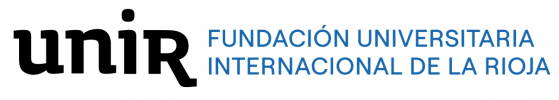

*****

<mark>NOTA:</mark> Como la guía de la actividad no fija un contenido mínimo, se toma como referente la estructura de contenido mínimo establecida para la Actividad 1. Este notebook es el anexo de código del informe: el informe expone la teoría, la metodología y el análisis, y cita las celdas de este notebook por su número de ejecución tras _Restart & Run All_.
*****

## 0. Configuración del entorno

Se importan las librerías, se definen las rutas de trabajo y se fijan los parámetros globales del experimento. Este notebook da continuidad a la Actividad 1 y usa su mismo entorno de trabajo; si falta algún conjunto de datos, se descarga con `preparar_act2.py`.

| Librería | Uso en este trabajo |
|---|---|
| `numpy` | Operaciones con matrices. **Todas las métricas de evaluación se implementan con NumPy** (sección 2) |
| `pandas` | Tablas de resultados por imagen, método y conjunto |
| `opencv-python` (`cv2`) | Lectura de imágenes, suavizado gaussiano, *black-hat* y operaciones morfológicas |
| `scipy` | Lectura de los `.mat` de CrackForest, etiquetado de componentes, transformada de distancia, correlación por FFT y prueba de Wilcoxon |
| `scikit-image` | Umbral de Otsu, gradiente de Sobel, Watershed, esqueletización y elemento estructurante circular |
| `matplotlib` | Figuras de los pasos intermedios y de los resultados |
| `hashlib`, `itertools`, `collections` | Huella MD5 de las anotaciones, rejilla de parámetros y cola del crecimiento de regiones |

**Parámetros globales**

- `SEMILLA = 2026`: fija el generador aleatorio, de modo que la partición de los datos es reproducible.
- `TOLERANCIA_PX = 2`: distancia máxima, en píxeles, a la que una detección cuenta como correcta en las métricas con tolerancia (sección 2.3).
- `SIGMA_SUAVIZADO = 1.0`: desviación típica del filtro gaussiano que precede al realce *black-hat* (secciones 1.2 y 3.1).

In [1]:
# Configuración del entorno de ejecución y comprobaciones iniciales

# --- Biblioteca estándar ---
import sys
import time
import hashlib
import itertools
from collections import deque
from pathlib import Path

# --- Cálculo numérico, estadística y tablas ---
import numpy as np
import pandas as pd
import scipy
import scipy.io as sio
from scipy import ndimage
from scipy.ndimage import distance_transform_edt
from scipy.signal import fftconvolve
from scipy.stats import wilcoxon

# --- Procesamiento de imagen ---
import cv2
import skimage
from skimage.filters import threshold_otsu, sobel
from skimage.morphology import disk, skeletonize
from skimage.segmentation import watershed, find_boundaries

# --- Figuras ---
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Rutas (relativas a la carpeta act1_au, donde está este notebook)
RUTA_CFD = Path("data")                   # CrackForest, el mismo de la Actividad 1
RUTA_DEEPCRACK = Path("data_deepcrack")   # DeepCrack, descargado para la Actividad 2
RUTA_RESULTADOS = Path("resultados_act2") # figuras y tablas para la memoria
RUTA_RESULTADOS.mkdir(exist_ok=True)

# Parámetros globales del experimento
SEMILLA = 2026          # partición de datos reproducible
TOLERANCIA_PX = 2       # tolerancia espacial de las métricas (sección 2.3)
SIGMA_SUAVIZADO = 1.0   # desviación típica (px) del suavizado gaussiano (secciones 1.2 y 3.1)

# Estilo de las figuras
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10})

# Comprobaciones: si falta una carpeta, el notebook se detiene con un mensaje claro
assert (RUTA_CFD / "groundTruth").is_dir(), "No se encuentra data/groundTruth (ejecuta preparar_act2.py)"
assert (RUTA_DEEPCRACK / "test_lab").is_dir(), "No se encuentra data_deepcrack (ejecuta preparar_act2.py)"

# Registro de versiones (reproducibilidad)
versiones = {
    "Python": sys.version.split()[0],
    "NumPy": np.__version__,
    "pandas": pd.__version__,
    "OpenCV": cv2.__version__,
    "SciPy": scipy.__version__,
    "scikit-image": skimage.__version__,
    "Matplotlib": matplotlib.__version__,
}
print("Entorno de ejecución:")
for libreria, version in versiones.items():
    print(f"  {libreria:13s} {version}")
print(f"\nSemilla: {SEMILLA} | Tolerancia de las métricas: {TOLERANCIA_PX} px")
print(f"Resultados en: {RUTA_RESULTADOS}/")

Entorno de ejecución:
  Python        3.14.6
  NumPy         2.5.3
  pandas        3.0.6
  OpenCV        5.0.0
  SciPy         1.18.1
  scikit-image  0.26.0
  Matplotlib    3.11.2

Semilla: 2026 | Tolerancia de las métricas: 2 px
Resultados en: resultados_act2/


## 1. Datos

### 1.1 Carga de los conjuntos de imágenes

`cargar_cfd` y `cargar_deepcrack` devuelven la imagen en escala de grises (`uint8`) y su *ground truth* en un **formato común**: una máscara booleana en la que `True` es fisura y `False` es fondo. Así, el resto del notebook trata igual los dos conjuntos, aunque codifiquen la anotación de forma distinta:

- CrackForest: matriz `Segmentation` del `.mat`, con $G = (\text{Segmentation} = 2)$.
- DeepCrack: PNG, con $G = (\text{etiqueta} > 127)$.

La celda inventaría solo las imágenes que tienen *ground truth* y comprueba, con una muestra de cada conjunto, que imagen y máscara se leen y tienen el mismo tamaño.

In [2]:
# Carga de imágenes y máscaras de fisura

def cargar_cfd(identificador):
    """Carga una muestra de CrackForest.

    Parámetros
    ----------
    identificador : str, número de la imagen con tres dígitos (p. ej. "049").

    Devuelve
    --------
    imagen : matriz uint8 en escala de grises.
    mascara : matriz booleana, True en los píxeles de fisura.
    """
    imagen = cv2.imread(str(RUTA_CFD / "image" / f"{identificador}.jpg"), cv2.IMREAD_GRAYSCALE)
    gt = sio.loadmat(RUTA_CFD / "groundTruth" / f"{identificador}.mat")
    mascara = gt["groundTruth"][0, 0]["Segmentation"] == 2      # 2 = fisura, 1 = fondo
    return imagen, mascara


def cargar_deepcrack(identificador, subconjunto):
    """Carga una muestra de DeepCrack.

    Parámetros
    ----------
    identificador : str, nombre del archivo sin extensión (p. ej. "11125-1").
    subconjunto : str, "train" o "test".

    Devuelve
    --------
    imagen : matriz uint8 en escala de grises.
    mascara : matriz booleana, True en los píxeles de fisura.
    """
    imagen = cv2.imread(str(RUTA_DEEPCRACK / f"{subconjunto}_img" / f"{identificador}.jpg"), cv2.IMREAD_GRAYSCALE)
    etiqueta = cv2.imread(str(RUTA_DEEPCRACK / f"{subconjunto}_lab" / f"{identificador}.png"), cv2.IMREAD_GRAYSCALE)
    mascara = etiqueta > 127                                    # blanco (255) = fisura
    return imagen, mascara


# Inventario: solo se consideran las imágenes que SÍ tienen ground truth
ids_cfd = sorted(p.stem for p in (RUTA_CFD / "groundTruth").glob("*.mat"))
ids_dc_train = sorted(p.stem for p in (RUTA_DEEPCRACK / "train_lab").glob("*.png"))
ids_dc_test = sorted(p.stem for p in (RUTA_DEEPCRACK / "test_lab").glob("*.png"))

print(f"CrackForest: {len(ids_cfd)} pares imagen + ground truth")
print(f"DeepCrack:   {len(ids_dc_train)} de entrenamiento + {len(ids_dc_test)} de prueba\n")

# Prueba de carga: una muestra de cada conjunto
for nombre, (img, gt) in [("CrackForest " + ids_cfd[0], cargar_cfd(ids_cfd[0])),
                          ("DeepCrack " + ids_dc_test[0], cargar_deepcrack(ids_dc_test[0], "test"))]:
    assert img is not None, f"No se pudo leer la imagen de {nombre}"
    assert img.shape == gt.shape, f"{nombre}: la imagen y la máscara tienen tamaños distintos"
    print(f"{nombre:22s} imagen {img.shape} {img.dtype} [{img.min()}-{img.max()}] | "
          f"máscara {gt.dtype}, fisura = {100 * gt.mean():.2f} % de los píxeles")

CrackForest: 118 pares imagen + ground truth
DeepCrack:   300 de entrenamiento + 237 de prueba

CrackForest 001        imagen (320, 480) uint8 [37-227] | máscara bool, fisura = 1.19 % de los píxeles
DeepCrack 111212-1     imagen (544, 384) uint8 [0-193] | máscara bool, fisura = 1.81 % de los píxeles


### 1.2 Control de calidad del *ground truth*

Antes de usar las anotaciones se revisan las 655 imágenes con *ground truth* (118 de CrackForest y 537 de DeepCrack) con dos criterios objetivos.

**Criterio 1, anotación duplicada.** Se calcula la huella MD5 de cada máscara. Si dos imágenes comparten huella, la anotación se asigna a la imagen donde mejor se ajusta (mayor contraste $C$, definido abajo) y las demás se excluyen.

**Criterio 2, anotación desalineada.** Sea $B$ el realce *black-hat* de la imagen (sección 3.1) y $E$ el esqueleto de la anotación. Para cada desplazamiento $\Delta = (d_y, d_x)$ con $|d_y|, |d_x| \le 30$ px se calcula el realce medio bajo el esqueleto desplazado:

$$
R(\Delta) = \frac{1}{|E|}\sum_{p \in E} B(p + \Delta)
\qquad
C = \frac{R(0)}{\overline{B}}
\qquad
g = \frac{\max_\Delta R(\Delta)}{R(0)}
$$

$R(\Delta)$ se obtiene para todos los desplazamientos a la vez como una correlación calculada con FFT. La anotación se considera desalineada si el mejor desplazamiento $\Delta^*$ supera la tolerancia de las métricas, $\max(|d_y^*|, |d_x^*|) > \tau = 2$ px, **y** desplazarla mejora claramente el ajuste, $g \ge 1{,}25$. La segunda condición evita excluir fisuras anchas, en las que el máximo puede caer en cualquier punto de su anchura sin que la anotación esté mal.

La figura muestra cada imagen excluida con el contorno de la anotación en magenta (con contraste realzado solo para visualizarla). La tabla completa se guarda en `control_calidad_ground_truth.csv`.

Imágenes revisadas: 655 (CrackForest 118, DeepCrack 537)

Ganancia del ajuste (percentiles 50 / 95 / máximo):
  CrackForest 1.00 / 1.13 / 2.14
  DeepCrack   1.00 / 1.03 / 1.20

Imágenes excluidas (3):
   Conjunto Imagen  Contraste  dy  dx  Ganancia                               Motivo
CrackForest    023       1.29  -2   3      1.35      anotación desplazada (-2, 3) px
CrackForest    042       0.96 -30 -16      1.54 anotación duplicada de la imagen 065
CrackForest    054       1.16   4   0      2.14       anotación desplazada (4, 0) px


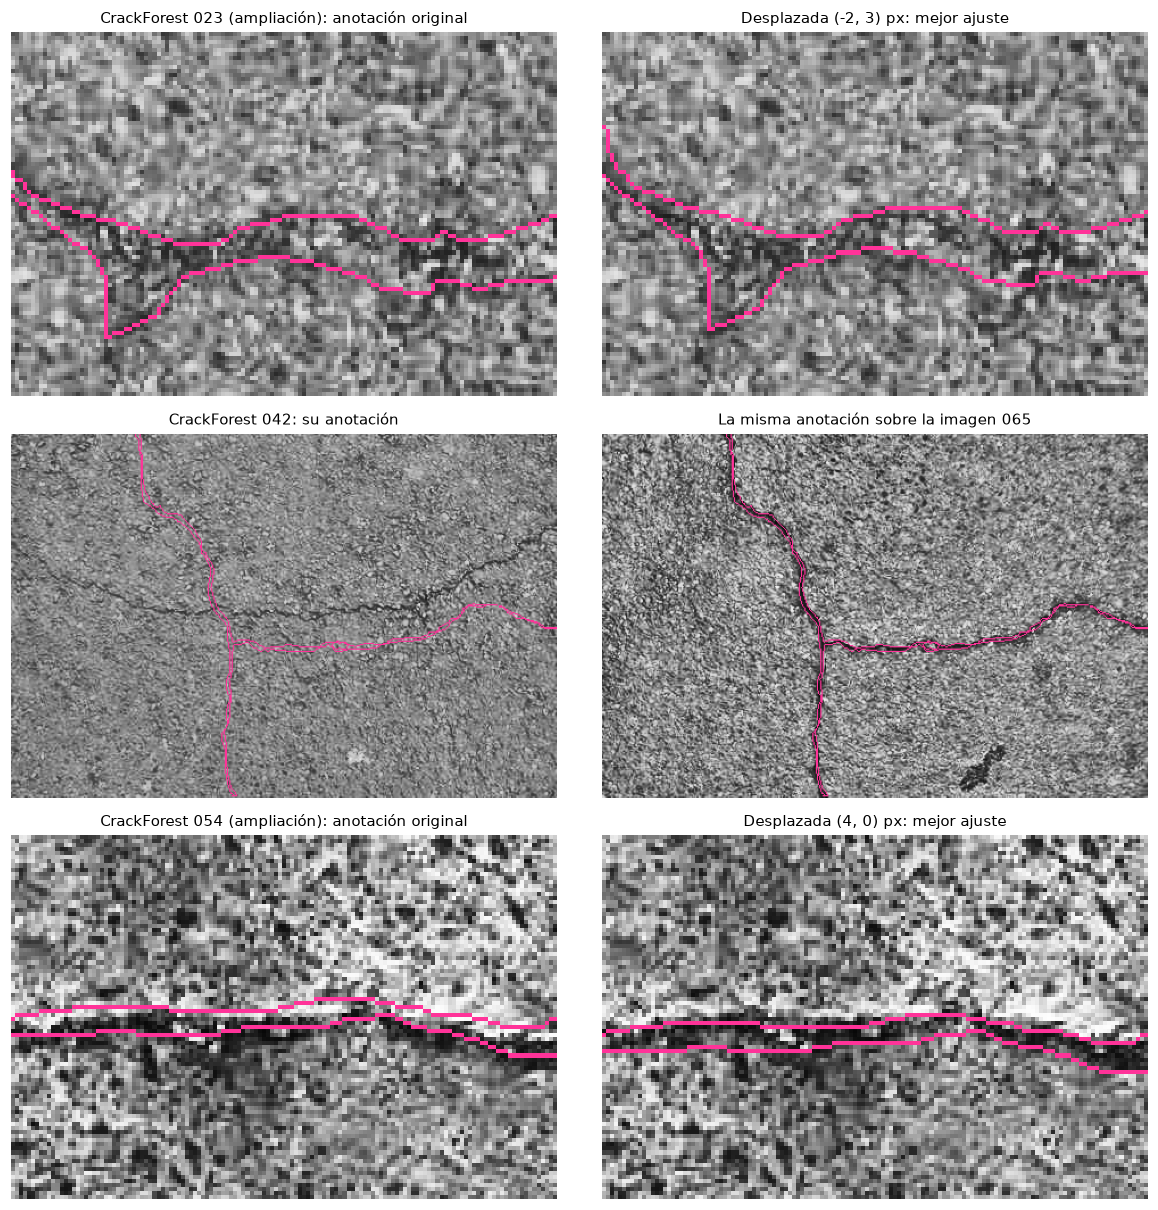

In [3]:
# Control de calidad del ground truth

UMBRAL_GANANCIA = 1.25      # mejora mínima del ajuste para considerar una anotación desalineada
DESPLAZAMIENTO_MAXIMO = 30  # desplazamiento explorado (px) en cada dirección
RADIO_CONTROL = {"CrackForest": 5, "DeepCrack": 20}   # radio del black-hat según el ancho típico de fisura


def cargar_muestra(conjunto, subconjunto, identificador):
    """Carga (imagen, máscara) de cualquiera de los dos conjuntos."""
    if conjunto == "CrackForest":
        return cargar_cfd(identificador)
    return cargar_deepcrack(identificador, subconjunto)


def ajuste_anotacion(img, gt, radio):
    """Mide cómo se ajusta la anotación a las estructuras oscuras y finas de la imagen.

    Desliza el eje (esqueleto) de la anotación en todas las posiciones hasta +-30 px y calcula,
    en cada una, el realce black-hat medio bajo el eje (correlación calculada con FFT).

    Devuelve
    --------
    contraste : float, realce medio bajo el eje en su posición original / realce medio de la imagen.
    dy, dx : int, desplazamiento (filas, columnas) con el mejor ajuste.
    ganancia : float, realce en la mejor posición / realce en la posición original.
    """
    suavizada = cv2.GaussianBlur(img, (0, 0), SIGMA_SUAVIZADO)          # mismo realce que en la sección 3.1
    realce = cv2.morphologyEx(suavizada, cv2.MORPH_BLACKHAT, disk(radio).astype(np.uint8)).astype(float)
    eje = skeletonize(gt).astype(float)
    correlacion = fftconvolve(realce, eje[::-1, ::-1], mode="same") / eje.sum()
    cf, cc = realce.shape[0] // 2, realce.shape[1] // 2          # posición de desplazamiento cero
    R = DESPLAZAMIENTO_MAXIMO
    ventana = correlacion[cf - R:cf + R + 1, cc - R:cc + R + 1]
    dy, dx = np.unravel_index(np.argmax(ventana), ventana.shape)
    original = ventana[R, R]
    return original / realce.mean(), int(dy - R), int(dx - R), ventana.max() / original


# --- Se revisan TODAS las imágenes con ground truth de ambos conjuntos ---
inventario = ([("CrackForest", None, i) for i in ids_cfd]
              + [("DeepCrack", "train", i) for i in ids_dc_train]
              + [("DeepCrack", "test", i) for i in ids_dc_test])
filas = []
for conjunto, subconjunto, id_imagen in inventario:
    img, gt = cargar_muestra(conjunto, subconjunto, id_imagen)
    contraste, dy, dx, ganancia = ajuste_anotacion(img, gt, RADIO_CONTROL[conjunto])
    filas.append({"Conjunto": conjunto, "Subconjunto": subconjunto or "-", "Imagen": id_imagen,
                  "Huella": hashlib.md5(np.packbits(gt).tobytes()).hexdigest(),
                  "Contraste": contraste, "dy": dy, "dx": dx, "Ganancia": ganancia})
calidad = pd.DataFrame(filas)

# --- Criterio 1: anotación duplicada. Dentro de cada grupo se excluyen las que no se ajustan a su imagen ---
calidad["Motivo"] = ""
for (conjunto, huella), grupo in calidad.groupby(["Conjunto", "Huella"]):
    if len(grupo) > 1:
        propietaria = grupo["Contraste"].idxmax()            # la imagen a la que sí pertenece la anotación
        for idx in grupo.index.drop(propietaria):
            calidad.loc[idx, "Motivo"] = f'anotación duplicada de la imagen {calidad.loc[propietaria, "Imagen"]}'

# --- Criterio 2: anotación desalineada (fuera de la tolerancia y con mejora clara al desplazarla) ---
desplazamiento = calidad[["dy", "dx"]].abs().max(axis=1)
desalineada = (desplazamiento > TOLERANCIA_PX) & (calidad["Ganancia"] >= UMBRAL_GANANCIA) & (calidad["Motivo"] == "")
calidad.loc[desalineada, "Motivo"] = ("anotación desplazada (" + calidad["dy"].astype(str) + ", "
                                      + calidad["dx"].astype(str) + ") px")

excluidas = calidad[calidad["Motivo"] != ""]
EXCLUIDAS = set(zip(excluidas["Conjunto"], excluidas["Subconjunto"], excluidas["Imagen"]))
calidad.drop(columns="Huella").to_csv(RUTA_RESULTADOS / "control_calidad_ground_truth.csv", index=False)

print(f"Imágenes revisadas: {len(calidad)} (CrackForest {sum(calidad.Conjunto == 'CrackForest')}, "
      f"DeepCrack {sum(calidad.Conjunto == 'DeepCrack')})")
print("\nGanancia del ajuste (percentiles 50 / 95 / máximo):")
for c, g in calidad.groupby("Conjunto"):
    print(f"  {c:11s} {g.Ganancia.median():.2f} / {g.Ganancia.quantile(0.95):.2f} / {g.Ganancia.max():.2f}")
print(f"\nImágenes excluidas ({len(excluidas)}):")
print(excluidas[["Conjunto", "Imagen", "Contraste", "dy", "dx", "Ganancia", "Motivo"]]
      .round(2).to_string(index=False))


# --- Evidencia visual de cada imagen excluida ---
clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))     # solo para ver mejor la fisura


def contorno_anotacion(img, gt):
    """Imagen con contraste realzado y el contorno de la anotación en magenta."""
    vista = np.dstack([clahe.apply(img) / 255.0] * 3)
    vista[find_boundaries(gt, mode="inner")] = (1.0, 0.2, 0.6)
    return vista


def recorte_centrado(gt, alto=90, ancho=135):
    """Ventana alto x ancho centrada en el píxel de la máscara más próximo a su punto mediano.
    También se usa para la ampliación de los mapas de errores (sección 2.6)."""
    if not gt.any():
        return slice(0, alto), slice(0, ancho)
    f, c = np.nonzero(gt)
    k = np.argmin((f - np.median(f)) ** 2 + (c - np.median(c)) ** 2)
    f0 = int(np.clip(f[k] - alto // 2, 0, gt.shape[0] - alto))
    c0 = int(np.clip(c[k] - ancho // 2, 0, gt.shape[1] - ancho))
    return slice(f0, f0 + alto), slice(c0, c0 + ancho)


fig, ejes = plt.subplots(len(excluidas), 2, figsize=(11, 3.7 * len(excluidas)), squeeze=False)
for fila, (_, caso) in enumerate(excluidas.iterrows()):
    subconjunto = None if caso["Subconjunto"] == "-" else caso["Subconjunto"]
    img, gt = cargar_muestra(caso["Conjunto"], subconjunto, caso["Imagen"])
    if caso["Motivo"].startswith("anotación duplicada"):
        gemela = caso["Motivo"].split()[-1]
        img_g, _ = cargar_muestra(caso["Conjunto"], subconjunto, gemela)
        ejes[fila, 0].imshow(contorno_anotacion(img, gt))
        ejes[fila, 0].set_title(f'{caso["Conjunto"]} {caso["Imagen"]}: su anotación')
        ejes[fila, 1].imshow(contorno_anotacion(img_g, gt))
        ejes[fila, 1].set_title(f"La misma anotación sobre la imagen {gemela}")
    else:
        zona = recorte_centrado(gt)
        movida = np.roll(gt, (caso["dy"], caso["dx"]), axis=(0, 1))
        ejes[fila, 0].imshow(contorno_anotacion(img, gt)[zona], interpolation="nearest")
        ejes[fila, 0].set_title(f'{caso["Conjunto"]} {caso["Imagen"]} (ampliación): anotación original')
        ejes[fila, 1].imshow(contorno_anotacion(img, movida)[zona], interpolation="nearest")
        ejes[fila, 1].set_title(f'Desplazada ({caso["dy"]}, {caso["dx"]}) px: mejor ajuste')
for eje in ejes.ravel():
    eje.axis("off")
plt.tight_layout()
plt.savefig(RUTA_RESULTADOS / "fig00_control_calidad.png", bbox_inches="tight")
plt.show()

### 1.3 Partición en calibración y evaluación

- **CrackForest:** se barajan los 118 identificadores con la semilla de la sección 0; los 20 primeros forman la calibración y el resto la evaluación.
- **DeepCrack:** se eligen 20 imágenes de *train* sin repetición para calibración; la evaluación es el *test* oficial completo.
- Las imágenes excluidas en la sección 1.2 se retiran **después** del sorteo, para no alterar la asignación de las demás.

**Independencia por contenido.** En DeepCrack, algunos nombres de archivo (serie `11289-*`) se repiten en *train* y *test* aunque son imágenes distintas. Por eso se compara el contenido: cada imagen se reduce a una miniatura $m$ de 32 × 32 px y se calcula, para cada par calibración–evaluación,

$$
d(a, b) = \frac{1}{32^2}\sum_{i,j} \lvert m_a(i,j) - m_b(i,j) \rvert
$$

Una imagen repetida, aunque se hubiera renombrado o recomprimido, daría $d \approx 0$; la celda se detiene si algún par tiene $d \le 1$ nivel de gris. La partición se guarda en `particion_datos.csv`.

In [4]:
# Partición en calibración y evaluación

def cargar_muestras(conjunto, identificadores, subconjunto=None):
    """Carga una lista de imágenes con su ground truth.

    Parámetros
    ----------
    conjunto : str, "CrackForest" o "DeepCrack".
    identificadores : lista de str con los nombres de las imágenes.
    subconjunto : str, "train" o "test" (solo para DeepCrack).

    Devuelve
    --------
    muestras : lista de diccionarios con las claves "conjunto", "id", "img" y "gt".
    """
    muestras = []
    for i in identificadores:
        imagen, mascara = cargar_muestra(conjunto, subconjunto, i)
        muestras.append({"conjunto": conjunto, "id": i, "img": imagen, "gt": mascara})
    return muestras


def miniatura(imagen):
    """Miniatura de 32 x 32 píxeles para comparar imágenes por su contenido."""
    return cv2.resize(imagen, (32, 32), interpolation=cv2.INTER_AREA).astype(float)


generador = np.random.default_rng(SEMILLA)

# --- CrackForest: se baraja la lista; las 20 primeras van a calibración y el resto a evaluación ---
ids_mezclados = generador.permutation(ids_cfd)
cfd_calibracion = sorted(str(i) for i in ids_mezclados[:20])
cfd_evaluacion = sorted(str(i) for i in ids_mezclados[20:])

# --- DeepCrack: 20 imágenes de train sin repetición; la evaluación usa el test oficial completo ---
dc_calibracion = sorted(str(i) for i in generador.choice(ids_dc_train, size=20, replace=False))
dc_evaluacion = list(ids_dc_test)

# --- Exclusión de las imágenes con ground truth defectuoso (sección 1.2) ---
# Se retiran DESPUÉS del sorteo para no alterar la asignación del resto de imágenes.
cfd_calibracion = [i for i in cfd_calibracion if ("CrackForest", "-", i) not in EXCLUIDAS]
cfd_evaluacion = [i for i in cfd_evaluacion if ("CrackForest", "-", i) not in EXCLUIDAS]
dc_calibracion = [i for i in dc_calibracion if ("DeepCrack", "train", i) not in EXCLUIDAS]
dc_evaluacion = [i for i in dc_evaluacion if ("DeepCrack", "test", i) not in EXCLUIDAS]

calibracion = (cargar_muestras("CrackForest", cfd_calibracion)
               + cargar_muestras("DeepCrack", dc_calibracion, "train"))
evaluacion = (cargar_muestras("CrackForest", cfd_evaluacion)
              + cargar_muestras("DeepCrack", dc_evaluacion, "test"))

# --- Independencia por CONTENIDO: diferencia media entre miniaturas (matriz calibración x evaluación) ---
mini_cal = np.array([miniatura(m["img"]) for m in calibracion])
mini_eva = np.array([miniatura(m["img"]) for m in evaluacion])
diferencias_miniaturas = np.abs(mini_cal[:, None] - mini_eva[None, :]).mean(axis=(2, 3))
assert diferencias_miniaturas.min() > 1.0, "Hay imágenes repetidas entre calibración y evaluación"
nombres_repetidos = sorted(set(dc_calibracion) & set(dc_evaluacion))

# --- Resumen y registro de la partición (verificable aunque cambie la versión de NumPy) ---
resumen_particion = pd.DataFrame({
    "Calibración": [len(cfd_calibracion), len(dc_calibracion)],
    "Evaluación": [len(cfd_evaluacion), len(dc_evaluacion)],
}, index=["CrackForest", "DeepCrack"])
resumen_particion.loc["Total"] = resumen_particion.sum()
pd.DataFrame(
    [{"conjunto": m["conjunto"], "id": m["id"], "subconjunto": "calibración"} for m in calibracion]
    + [{"conjunto": m["conjunto"], "id": m["id"], "subconjunto": "evaluación"} for m in evaluacion]
).to_csv(RUTA_RESULTADOS / "particion_datos.csv", index=False)

print(resumen_particion, "\n")
print(f"Diferencia mínima entre una imagen de calibración y una de evaluación: "
      f"{diferencias_miniaturas.min():.1f} niveles de gris (umbral de duplicado: 1.0)")
print(f"DeepCrack: {len(nombres_repetidos)} nombres coinciden entre calibración y evaluación "
      f"({', '.join(nombres_repetidos)}), pero son imágenes distintas.")
print(f"\nCalibración CrackForest: {', '.join(cfd_calibracion)}")
print(f"Partición guardada en {RUTA_RESULTADOS}/particion_datos.csv")

             Calibración  Evaluación
CrackForest           20          95
DeepCrack             20         237
Total                 40         332 

Diferencia mínima entre una imagen de calibración y una de evaluación: 3.5 niveles de gris (umbral de duplicado: 1.0)
DeepCrack: 2 nombres coinciden entre calibración y evaluación (11289-7, 11289-9), pero son imágenes distintas.

Calibración CrackForest: 011, 013, 017, 018, 020, 026, 032, 048, 049, 059, 068, 069, 070, 074, 075, 077, 094, 095, 099, 116
Partición guardada en resultados_act2/particion_datos.csv


### 1.4 Exploración visual

Para cada conjunto se muestran las dos imágenes de calibración con **menor** y **mayor** proporción de fisura. Elegirlas con un criterio numérico, y no a mano, muestra el rango de dificultad sin sesgar la selección.

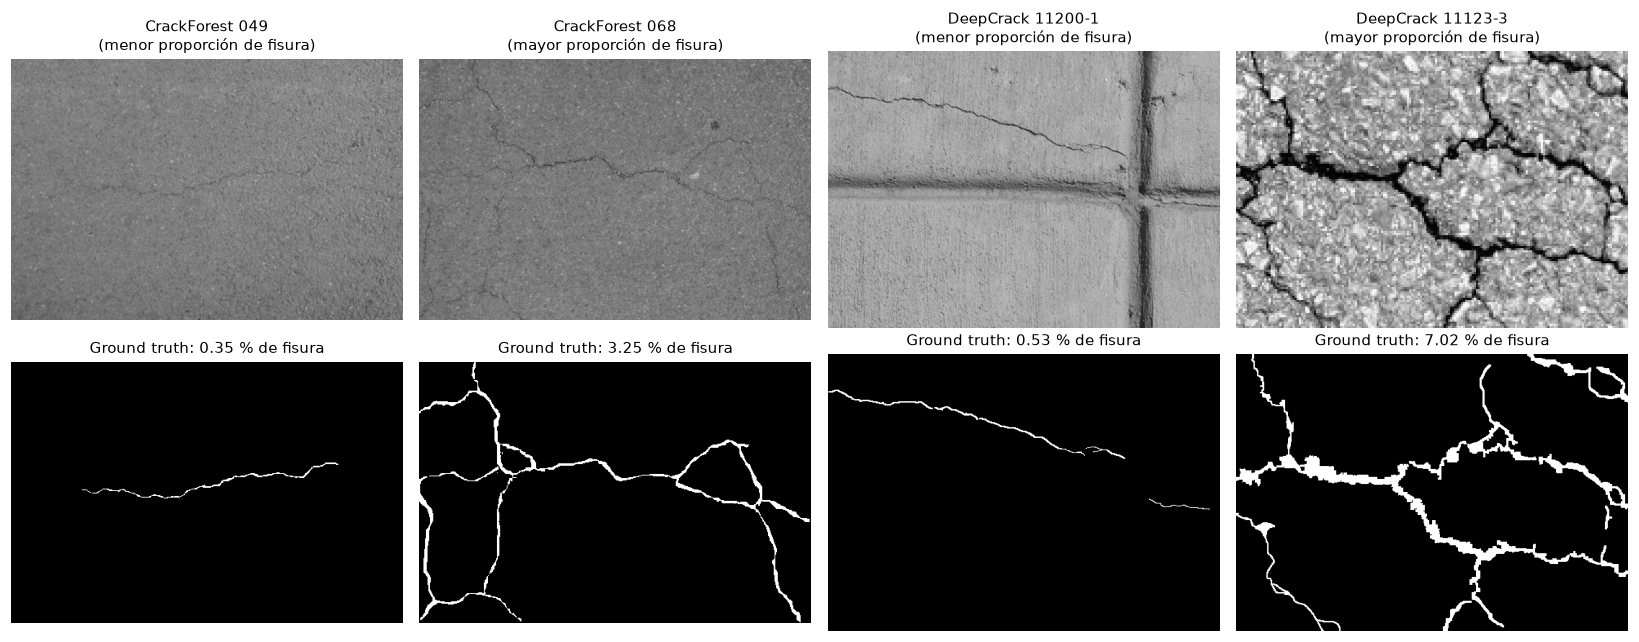

In [5]:
# Exploración visual de los conjuntos de datos

# Para cada conjunto se eligen las imágenes de calibración con MENOR y MAYOR
# proporción de fisura: un criterio objetivo que cubre el rango de dificultad.
ejemplos = []
for conjunto in ["CrackForest", "DeepCrack"]:
    muestras = sorted((m for m in calibracion if m["conjunto"] == conjunto),
                      key=lambda m: m["gt"].mean())
    ejemplos += [(muestras[0], "menor proporción de fisura"),
                 (muestras[-1], "mayor proporción de fisura")]

fig, ejes = plt.subplots(2, 4, figsize=(15, 6))
for col, (m, criterio) in enumerate(ejemplos):
    ejes[0, col].imshow(m["img"], cmap="gray", vmin=0, vmax=255)
    ejes[0, col].set_title(f'{m["conjunto"]} {m["id"]}\n({criterio})')
    ejes[1, col].imshow(m["gt"], cmap="gray")
    ejes[1, col].set_title(f'Ground truth: {100 * m["gt"].mean():.2f} % de fisura')
for eje in ejes.ravel():
    eje.axis("off")
plt.tight_layout()
plt.savefig(RUTA_RESULTADOS / "fig01_ejemplos_conjuntos.png", bbox_inches="tight")
plt.show()

### 1.5 Caracterización cuantitativa del *ground truth*

Se calculan dos propiedades de cada máscara $G$ de las 372 imágenes utilizadas:

$$
\text{Fisura (\%)} = 100\,\frac{\lvert G \rvert}{N}
\qquad
\bar{a} = \frac{2}{\lvert E \rvert}\sum_{p \in E} D_G(p)
$$

donde $N$ es el número de píxeles, $E$ el esqueleto de $G$ (eje medial; Blum, 1967) y $D_G(p)$ la distancia de $p$ al fondo más cercano (transformada de distancia euclídea). Sobre el eje, $D_G$ es la mitad del ancho local, por eso el ancho medio es el doble de su promedio. La tabla resume mediana, mínimo y máximo; el histograma agrupa en la última barra los anchos $\ge 30$ px.

            Fisura (%)               Ancho medio (px)              
               Mediana Mínimo Máximo          Mediana Mínimo Máximo
Conjunto                                                           
CrackForest       1.30   0.35   6.33             3.22   2.08   6.03
DeepCrack         3.34   0.53  19.25             7.90   2.35  50.14 



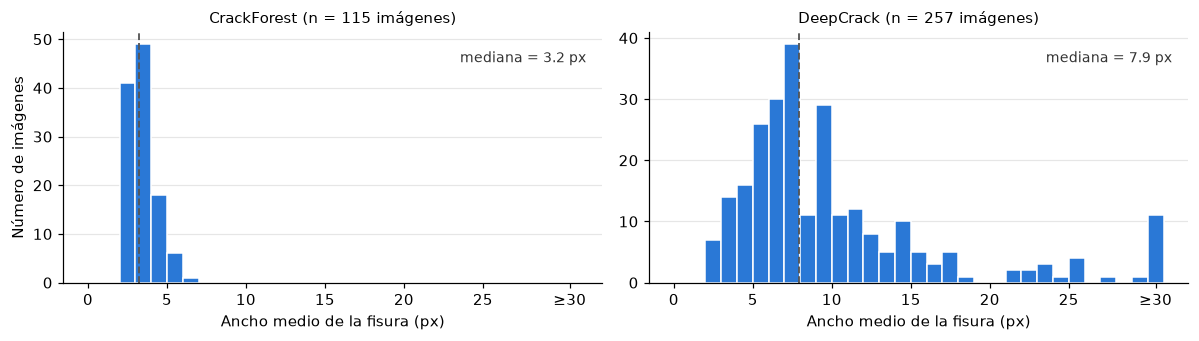

In [6]:
# Caracterización cuantitativa del ground truth

def ancho_medio_fisura(mascara):
    """Ancho medio de la fisura en píxeles, por el método del eje medial.

    Parámetros
    ----------
    mascara : matriz booleana, True en los píxeles de fisura.

    Devuelve
    --------
    ancho : float, 2 x distancia media del eje (esqueleto) al borde de la fisura.
    """
    # Primero se obtiene el esqueleto de la fisura, su línea central de 1 píxel de grosor.
    esqueleto = skeletonize(mascara)
    if not esqueleto.any():
        return np.nan
    # Se asigna a cada píxel de fisura su distancia al fondo más cercano. 
    # Sobre el esqueleto, esa distancia equivale a la mitad del ancho local, 
    # por lo que el ancho medio es el doble del promedio de esas distancias.
    distancia_al_borde = distance_transform_edt(mascara) 
    return 2 * distancia_al_borde[esqueleto].mean()


# --- Tabla imagen por imagen ---
caracteristicas = pd.DataFrame([
    {"Conjunto": m["conjunto"], "Imagen": m["id"],
     "Fisura (%)": 100 * m["gt"].mean(),
     "Ancho medio (px)": ancho_medio_fisura(m["gt"])}
    for m in calibracion + evaluacion
])
caracteristicas.to_csv(RUTA_RESULTADOS / "caracterizacion_ground_truth.csv", index=False)

# --- Resumen por conjunto ---
resumen_caracteristicas = (caracteristicas
                           .groupby("Conjunto")[["Fisura (%)", "Ancho medio (px)"]]
                           .agg(["median", "min", "max"])
                           .rename(columns={"median": "Mediana", "min": "Mínimo", "max": "Máximo"})
                           .round(2))
print(resumen_caracteristicas.to_string(), "\n")

# --- Distribución del ancho medio: un panel por conjunto, misma escala horizontal ---
ANCHO_MAXIMO_GRAFICO = 30          # los anchos mayores se agrupan en la última barra
COLOR_BARRAS = "#2a78d6"
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.2), sharex=True)
for eje, conjunto in zip(ejes, ["CrackForest", "DeepCrack"]):
    anchos = caracteristicas.loc[caracteristicas["Conjunto"] == conjunto, "Ancho medio (px)"]
    eje.hist(anchos.clip(upper=ANCHO_MAXIMO_GRAFICO), bins=np.arange(0, ANCHO_MAXIMO_GRAFICO + 2, 1),
             color=COLOR_BARRAS, edgecolor="white", linewidth=1)
    mediana = anchos.median()
    eje.axvline(mediana, color="#555555", linestyle="--", linewidth=1.2)
    eje.text(0.97, 0.88, f"mediana = {mediana:.1f} px", transform=eje.transAxes,
             ha="right", color="#333333", fontsize=9)
    eje.set_title(f"{conjunto} (n = {len(anchos)} imágenes)")
    eje.set_xlabel("Ancho medio de la fisura (px)")
    eje.set_xticks([0, 5, 10, 15, 20, 25, ANCHO_MAXIMO_GRAFICO + 0.5],
                   ["0", "5", "10", "15", "20", "25", f"≥{ANCHO_MAXIMO_GRAFICO}"])
    eje.spines[["top", "right"]].set_visible(False)
    eje.grid(axis="y", color="#e6e6e6", linewidth=0.8)
    eje.set_axisbelow(True)
ejes[0].set_ylabel("Número de imágenes")
plt.tight_layout()
plt.savefig(RUTA_RESULTADOS / "fig02_ancho_fisuras.png", bbox_inches="tight")
plt.show()

## 2. Evaluador propio

Todas las métricas se programan con operaciones de NumPy, sin bibliotecas de métricas como `scikit-learn`. Solo se usan dos operadores geométricos auxiliares que no calculan ninguna métrica: la transformada de distancia (SciPy) y la esqueletización (scikit-image, método de Zhang y Suen, 1984). En adelante, $S$ es la máscara del segmentador y $G$ la de *ground truth*: matrices booleanas del mismo tamaño en las que `True` es fisura.

### 2.1 Matriz de confusión píxel a píxel

$$
TP = \lvert S \cap G \rvert \qquad FP = \lvert S \setminus G \rvert \qquad FN = \lvert G \setminus S \rvert \qquad TN = \lvert \overline{S} \cap \overline{G} \rvert
$$

Cada conjunto se calcula con operaciones lógicas elemento a elemento (`&`, `~`) y se cuenta con `np.sum`. El ejemplo de 2 × 4 píxeles del final se resuelve a mano en la sección 2.4.

In [7]:
# Matriz de confusión

def matriz_confusion(S, G):
    """Cuenta los cuatro casos posibles al comparar dos máscaras píxel a píxel.

    Parámetros
    ----------
    S : matriz booleana, máscara producida por el segmentador (True = fisura).
    G : matriz booleana, máscara de ground truth (True = fisura).

    Devuelve
    --------
    TP, FP, FN, TN : int, número de verdaderos positivos, falsos positivos,
        falsos negativos y verdaderos negativos.
    """
    if S.shape != G.shape:
        raise ValueError(f"Tamaños distintos: S {S.shape} y G {G.shape}")
    S = S.astype(bool)
    G = G.astype(bool)
    TP = int(np.sum(S & G))       # fisura detectada correctamente
    FP = int(np.sum(S & ~G))      # fondo marcado como fisura (falsa alarma)
    FN = int(np.sum(~S & G))      # fisura no detectada
    TN = int(np.sum(~S & ~G))     # fondo reconocido como fondo
    return TP, FP, FN, TN


# --- Ejemplo de 2 x 4 píxeles calculado a mano (se verifica en la sección 2.4) ---
S_ejemplo = np.array([[1, 1, 1, 0],
                      [0, 0, 0, 0]], dtype=bool)
G_ejemplo = np.array([[0, 1, 1, 1],
                      [0, 0, 0, 0]], dtype=bool)
TP, FP, FN, TN = matriz_confusion(S_ejemplo, G_ejemplo)
print(f"TP = {TP}, FP = {FP}, FN = {FN}, TN = {TN}  (total = {TP + FP + FN + TN} píxeles)")

TP = 2, FP = 1, FN = 1, TN = 4  (total = 8 píxeles)


### 2.2 Métricas de solapamiento estricto

$$
\text{IoU} = \frac{TP}{TP+FP+FN} \qquad
\text{Dice} = \frac{2\,TP}{2\,TP+FP+FN} \qquad
\text{Exactitud} = \frac{TP+TN}{TP+FP+FN+TN}
$$

$$
\text{Precisión} = \frac{TP}{TP+FP} \qquad
\text{Sensibilidad} = \frac{TP}{TP+FN}
$$

`division_segura` aplica la convención de casos límite cuando un denominador es 0: la métrica vale 1 si $S$ y $G$ están vacías y 0 en otro caso. La demostración final aplica un segmentador "nulo" (máscara vacía) a las 40 imágenes de calibración para cuantificar por qué la exactitud no sirve con clases tan desbalanceadas.

In [8]:
# Métricas de solapamiento estricto

def division_segura(numerador, denominador, valor_si_cero):
    """Divide; si el denominador es 0, devuelve el valor fijado por la convención de casos límite."""
    return numerador / denominador if denominador > 0 else valor_si_cero


def metricas_solapamiento(S, G):
    """Métricas de solapamiento estricto, píxel a píxel.

    Parámetros
    ----------
    S : matriz booleana, máscara del segmentador.
    G : matriz booleana, máscara de ground truth.

    Devuelve
    --------
    resultado : diccionario con TP, FP, FN, TN, IoU, Dice, Precision, Sensibilidad y Exactitud.
    """
    TP, FP, FN, TN = matriz_confusion(S, G)
    ambas_vacias = (TP + FP + FN) == 0          # ni S ni G contienen fisura
    valor_limite = 1.0 if ambas_vacias else 0.0
    return {
        "TP": TP, "FP": FP, "FN": FN, "TN": TN,
        "IoU": division_segura(TP, TP + FP + FN, valor_limite),
        "Dice": division_segura(2 * TP, 2 * TP + FP + FN, valor_limite),
        "Precision": division_segura(TP, TP + FP, valor_limite),
        "Sensibilidad": division_segura(TP, TP + FN, valor_limite),
        "Exactitud": (TP + TN) / (TP + FP + FN + TN),
    }


# Demostración: un segmentador "nulo" que nunca detecta fisura
filas = []
for m in calibracion:
    S_nula = np.zeros_like(m["gt"])            # máscara vacía del mismo tamaño
    r = metricas_solapamiento(S_nula, m["gt"])
    filas.append({"Conjunto": m["conjunto"], "Exactitud": r["Exactitud"], "IoU": r["IoU"],
                  "Dice": r["Dice"], "Sensibilidad": r["Sensibilidad"]})
demo_nulo = pd.DataFrame(filas).groupby("Conjunto").mean().round(3)
print("\nSegmentador nulo (no detecta nada) sobre las 40 imágenes de calibración:")
print(demo_nulo.to_string())


Segmentador nulo (no detecta nada) sobre las 40 imágenes de calibración:
             Exactitud  IoU  Dice  Sensibilidad
Conjunto                                       
CrackForest      0.986  0.0   0.0           0.0
DeepCrack        0.967  0.0   0.0           0.0


### 2.3 Métricas para estructuras finas

**F1 con tolerancia espacial ($F1_\tau$).** Con $d(p, X)$ la distancia del píxel $p$ al píxel más cercano de la máscara $X$:

$$
P_\tau = \frac{\lvert\{p \in S : d(p, G) \le \tau\}\rvert}{\lvert S\rvert} \qquad
R_\tau = \frac{\lvert\{p \in G : d(p, S) \le \tau\}\rvert}{\lvert G\rvert} \qquad
F1_\tau = \frac{2\,P_\tau\,R_\tau}{P_\tau + R_\tau}
$$

Las distancias $d(\cdot, G)$ y $d(\cdot, S)$ se obtienen para toda la imagen con una transformada de distancia sobre el complemento de cada máscara. Se usa $\tau = 2$ px: con un ancho mediano de 3,22 px en CrackForest, tolera la imprecisión de la anotación (1–2 px) sin aceptar detecciones situadas a más de una fisura de distancia.

**clDice.** Con $\mathrm{esq}(X)$ el esqueleto de la máscara $X$:

$$
T_{prec} = \frac{\lvert \mathrm{esq}(S) \cap G \rvert}{\lvert \mathrm{esq}(S) \rvert} \qquad
T_{sens} = \frac{\lvert \mathrm{esq}(G) \cap S \rvert}{\lvert \mathrm{esq}(G) \rvert} \qquad
\text{clDice} = \frac{2\,T_{prec}\,T_{sens}}{T_{prec}+T_{sens}}
$$

$T_{prec}$ es la parte del eje de la detección que cae dentro de la fisura real, y $T_{sens}$ la parte del eje de la fisura real cubierta por la detección. `evaluar` reúne en un solo diccionario todas las métricas de las secciones 2.1 a 2.3; es el único punto de entrada que usa el resto del notebook.

In [9]:
# Métricas de solapamiento con tolerancia espacial

def f1_con_tolerancia(S, G, tau=TOLERANCIA_PX):
    """Precisión, sensibilidad y F1 con tolerancia espacial.

    Un píxel de S se considera correcto si hay un píxel de fisura de G a una
    distancia <= tau, y un píxel de G se considera detectado si hay un píxel
    de S a una distancia <= tau.

    Parámetros
    ----------
    S : matriz booleana, máscara del segmentador.
    G : matriz booleana, máscara de ground truth.
    tau : float, tolerancia en píxeles.

    Devuelve
    --------
    resultado : diccionario con P_tol, R_tol y F1_tol.
    """
    S = S.astype(bool)
    G = G.astype(bool)
    if not S.any() and not G.any():                       # ambas vacías: acuerdo perfecto
        return {"P_tol": 1.0, "R_tol": 1.0, "F1_tol": 1.0}
    if not S.any() or not G.any():                        # solo una vacía
        return {"P_tol": 0.0, "R_tol": 0.0, "F1_tol": 0.0}
    distancia_a_G = distance_transform_edt(~G)            # distancia de cada píxel a la fisura real más cercana
    distancia_a_S = distance_transform_edt(~S)            # distancia de cada píxel a la fisura detectada más cercana
    P = float(np.mean(distancia_a_G[S] <= tau))           # detecciones con una fisura real cerca
    R = float(np.mean(distancia_a_S[G] <= tau))           # fisura real con una detección cerca
    F1 = division_segura(2 * P * R, P + R, 0.0)
    return {"P_tol": P, "R_tol": R, "F1_tol": F1}


def cldice(S, G):
    """clDice: coincidencia de las líneas centrales (esqueletos) de S y G.

    Parámetros
    ----------
    S : matriz booleana, máscara del segmentador.
    G : matriz booleana, máscara de ground truth.

    Devuelve
    --------
    valor : float entre 0 y 1.
    """
    S = S.astype(bool)
    G = G.astype(bool)
    if not S.any() and not G.any():
        return 1.0
    if not S.any() or not G.any():
        return 0.0
    esqueleto_S = skeletonize(S)
    esqueleto_G = skeletonize(G)
    T_prec = np.sum(esqueleto_S & G) / np.sum(esqueleto_S)   # eje de S que cae dentro de G
    T_sens = np.sum(esqueleto_G & S) / np.sum(esqueleto_G)   # eje de G que queda cubierto por S
    return float(division_segura(2 * T_prec * T_sens, T_prec + T_sens, 0.0))


def evaluar(S, G, tau=TOLERANCIA_PX):
    """Punto de entrada único del evaluador: devuelve todas las métricas en un diccionario."""
    resultado = metricas_solapamiento(S, G)
    resultado.update(f1_con_tolerancia(S, G, tau))
    resultado["clDice"] = cldice(S, G)
    return resultado

### 2.4 Validación del evaluador

Antes de evaluar los segmentadores se comprueba que el evaluador da el resultado correcto en 12 casos cuya respuesta se conoce de antemano. Si alguno falla, el `assert` detiene la ejecución.

- **Casos extremos (1, 2, 7, 8):** máscaras idénticas, disjuntas y vacías, incluida la convención de casos límite.
- **Ejemplo calculado a mano (3–6).** En el ejemplo de 2 × 4 píxeles de la sección 2.1, $S$ y $G$ marcan 3 píxeles cada una y comparten 2:

$$
TP=2,\; FP=1,\; FN=1,\; TN=4 \;\Rightarrow\;
\text{IoU}=\tfrac{2}{4},\;
\text{Dice}=\tfrac{4}{6},\;
\text{Precisión}=\text{Sensibilidad}=\tfrac{2}{3},\;
\text{Exactitud}=\tfrac{6}{8}
$$

- **Propiedades teóricas (9, 10):** la relación $\text{Dice} = 2\,\text{IoU}/(1+\text{IoU})$ en 200 pares aleatorios, y la simetría: IoU, Dice, $F1_\tau$ y clDice no cambian al intercambiar $S$ y $G$, mientras que Precisión y Sensibilidad se intercambian.
- **Estructuras finas (11, 12):** una línea de 1 px desplazada 1 px tiene IoU = 0 pero $F1_\tau = 1$; una línea engrosada a 3 px conserva un clDice cercano a 1, porque su eje coincide.

In [10]:
# Validación del evaluador con casos de resultado conocido

def comprobar(condicion, descripcion):
    """Detiene el notebook si la condición no se cumple; si se cumple, la registra."""
    assert condicion, f"FALLO: {descripcion}"
    print(f"  ✓ {descripcion}")


METRICAS_EVALUADOR = ["IoU", "Dice", "Precision", "Sensibilidad", "F1_tol", "clDice"]
banda = np.zeros((50, 50), bool); banda[20:30, 10:40] = True      # objeto de prueba de 10 x 30 px
lejana = np.zeros((50, 50), bool); lejana[0:5, 0:5] = True        # objeto alejado de la banda
vacia = np.zeros((20, 20), bool)
con_fisura = vacia.copy(); con_fisura[10, 2:18] = True
linea = np.zeros((40, 40), bool); linea[20, 5:35] = True          # fisura ideal de 1 px de ancho
linea_gruesa = cv2.dilate(linea.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)

print("Validación del evaluador")
r = evaluar(banda, banda)
comprobar(all(np.isclose(r[k], 1) for k in METRICAS_EVALUADOR), "1. Máscaras idénticas: todas las métricas valen 1")
r = evaluar(lejana, banda)
comprobar(r["IoU"] == r["Dice"] == r["F1_tol"] == r["clDice"] == 0, "2. Máscaras disjuntas y alejadas: IoU = Dice = F1_tol = clDice = 0")

r = evaluar(S_ejemplo, G_ejemplo)                                  # ejemplo 2 x 4 de la sección 2.1
comprobar((r["TP"], r["FP"], r["FN"], r["TN"]) == (2, 1, 1, 4), "3. Ejemplo a mano: TP = 2, FP = 1, FN = 1, TN = 4")
comprobar(np.isclose(r["IoU"], 2 / 4) and np.isclose(r["Dice"], 4 / 6), "4. Ejemplo a mano: IoU = 2/4 y Dice = 4/6")
comprobar(np.isclose(r["Precision"], 2 / 3) and np.isclose(r["Sensibilidad"], 2 / 3), "5. Ejemplo a mano: Precisión = Sensibilidad = 2/3")
comprobar(np.isclose(r["Exactitud"], 6 / 8), "6. Ejemplo a mano: Exactitud = 6/8")

r = evaluar(vacia, vacia)
comprobar(all(r[k] == 1 for k in METRICAS_EVALUADOR), "7. S y G vacías: todas las métricas valen 1 (convención)")
comprobar(evaluar(vacia, con_fisura)["Dice"] == 0 and evaluar(con_fisura, vacia)["F1_tol"] == 0,
          "8. Solo una máscara vacía: las métricas valen 0 (convención)")

rng = np.random.default_rng(0)
pares = [(rng.random((40, 40)) > 0.7, rng.random((40, 40)) > 0.7) for _ in range(200)]
comprobar(all(np.isclose(r["Dice"], 2 * r["IoU"] / (1 + r["IoU"])) for r in (evaluar(S, G) for S, G in pares)),
          "9. Dice = 2·IoU/(1 + IoU) en 200 pares de máscaras aleatorias")
r_sg, r_gs = evaluar(pares[0][0], pares[0][1]), evaluar(pares[0][1], pares[0][0])
comprobar(all(np.isclose(r_sg[k], r_gs[k]) for k in ["IoU", "Dice", "F1_tol", "clDice"])
          and np.isclose(r_sg["Precision"], r_gs["Sensibilidad"]),
          "10. Simetría: IoU, Dice, F1_tol y clDice no cambian al intercambiar S y G; Precisión(S, G) = Sensibilidad(G, S)")

r = evaluar(np.roll(linea, 1, axis=0), linea)
comprobar(r["IoU"] == 0 and r["F1_tol"] == 1, "11. Línea de 1 px desplazada 1 px: IoU = 0, pero F1_tol = 1")
r = evaluar(linea_gruesa, linea)
comprobar(r["clDice"] >= 0.9 and r["IoU"] < 0.4,
          f'12. Línea engrosada a 3 px: clDice = {r["clDice"]:.2f} (sigue el eje) e IoU = {r["IoU"]:.2f}')

print("\nEl evaluador supera las 12 comprobaciones.")

Validación del evaluador
  ✓ 1. Máscaras idénticas: todas las métricas valen 1
  ✓ 2. Máscaras disjuntas y alejadas: IoU = Dice = F1_tol = clDice = 0
  ✓ 3. Ejemplo a mano: TP = 2, FP = 1, FN = 1, TN = 4
  ✓ 4. Ejemplo a mano: IoU = 2/4 y Dice = 4/6
  ✓ 5. Ejemplo a mano: Precisión = Sensibilidad = 2/3
  ✓ 6. Ejemplo a mano: Exactitud = 6/8
  ✓ 7. S y G vacías: todas las métricas valen 1 (convención)
  ✓ 8. Solo una máscara vacía: las métricas valen 0 (convención)
  ✓ 9. Dice = 2·IoU/(1 + IoU) en 200 pares de máscaras aleatorias
  ✓ 10. Simetría: IoU, Dice, F1_tol y clDice no cambian al intercambiar S y G; Precisión(S, G) = Sensibilidad(G, S)
  ✓ 11. Línea de 1 px desplazada 1 px: IoU = 0, pero F1_tol = 1
  ✓ 12. Línea engrosada a 3 px: clDice = 0.97 (sigue el eje) e IoU = 0.31

El evaluador supera las 12 comprobaciones.


### 2.5 Sensibilidad de las métricas ante pequeños errores de borde

Se simula una segmentación "casi correcta" perturbando el propio *ground truth* de cada una de las 40 imágenes de calibración y evaluándolo como si fuera la salida de un segmentador:

- `desplazar(G, k)`: traslación de $k = 1, 2, 3$ filas (error de localización);
- engrosar o adelgazar 1 px: dilatación $G \oplus K$ y erosión $G \ominus K$ con un elemento estructurante $K$ de 3 × 3 (error de anchura).

La tabla da la media de cada métrica por conjunto y perturbación, y se guarda en `tabla_sensibilidad_metricas.csv`. Su interpretación está en el informe (apartado 2).

In [11]:
# Sensibilidad de las métricas ante pequeños errores de borde

def desplazar(mascara, pixeles):
    """Desplaza la máscara 'pixeles' filas hacia abajo (simula un error de localización)."""
    return np.roll(mascara, pixeles, axis=0)


NUCLEO_3x3 = np.ones((3, 3), np.uint8)
PERTURBACIONES = {
    "Desplazada 1 px": lambda g: desplazar(g, 1),
    "Desplazada 2 px": lambda g: desplazar(g, 2),
    "Desplazada 3 px": lambda g: desplazar(g, 3),
    "Engrosada 1 px": lambda g: cv2.dilate(g.astype(np.uint8), NUCLEO_3x3).astype(bool),
    "Adelgazada 1 px": lambda g: cv2.erode(g.astype(np.uint8), NUCLEO_3x3).astype(bool),
}

filas = []
for m in calibracion:                                   # 20 imágenes de calibración por conjunto
    for nombre, perturbar in PERTURBACIONES.items():
        r = evaluar(perturbar(m["gt"]), m["gt"])        # el GT perturbado hace de "segmentación"
        filas.append({"Conjunto": m["conjunto"], "Perturbación": nombre, "Exactitud": r["Exactitud"],
                      "IoU": r["IoU"], "Dice": r["Dice"], "F1_tol": r["F1_tol"], "clDice": r["clDice"]})

tabla_sensibilidad = (pd.DataFrame(filas)
                      .groupby(["Conjunto", "Perturbación"], sort=False).mean().round(3))
tabla_sensibilidad.to_csv(RUTA_RESULTADOS / "tabla_sensibilidad_metricas.csv")
print("Media de cada métrica sobre las 20 imágenes de calibración de cada conjunto:\n")
print(tabla_sensibilidad.to_string())

Media de cada métrica sobre las 20 imágenes de calibración de cada conjunto:

                             Exactitud    IoU   Dice  F1_tol  clDice
Conjunto    Perturbación                                            
CrackForest Desplazada 1 px      0.993  0.561  0.711   1.000   0.790
            Desplazada 2 px      0.987  0.308  0.451   1.000   0.370
            Desplazada 3 px      0.982  0.174  0.274   0.738   0.202
            Engrosada 1 px       0.989  0.539  0.698   1.000   0.994
            Adelgazada 1 px      0.990  0.226  0.353   0.782   0.585
DeepCrack   Desplazada 1 px      0.994  0.769  0.858   0.999   0.913
            Desplazada 2 px      0.989  0.614  0.730   0.999   0.764
            Desplazada 3 px      0.983  0.508  0.630   0.882   0.673
            Engrosada 1 px       0.990  0.711  0.823   1.000   0.992
            Adelgazada 1 px      0.990  0.566  0.677   0.880   0.805


### 2.6 Visualización de errores

`superposicion_errores` colorea cada píxel según su caso de la matriz de confusión: TP en verde, FP en naranja, FN en azul y TN en negro (paleta comprobada para daltonismo). `mostrar_evaluacion` presenta, en una fila, la imagen, el *ground truth*, el mapa de errores con sus métricas y una ampliación centrada en la fisura (`recorte_centrado`, sección 1.2). La prueba final usa un *ground truth* desplazado 2 px: el mapa muestra las franjas de FP y FN paralelas, y el título, el contraste entre IoU y $F1_\tau$. Esta convención de colores se usa en todas las figuras siguientes.

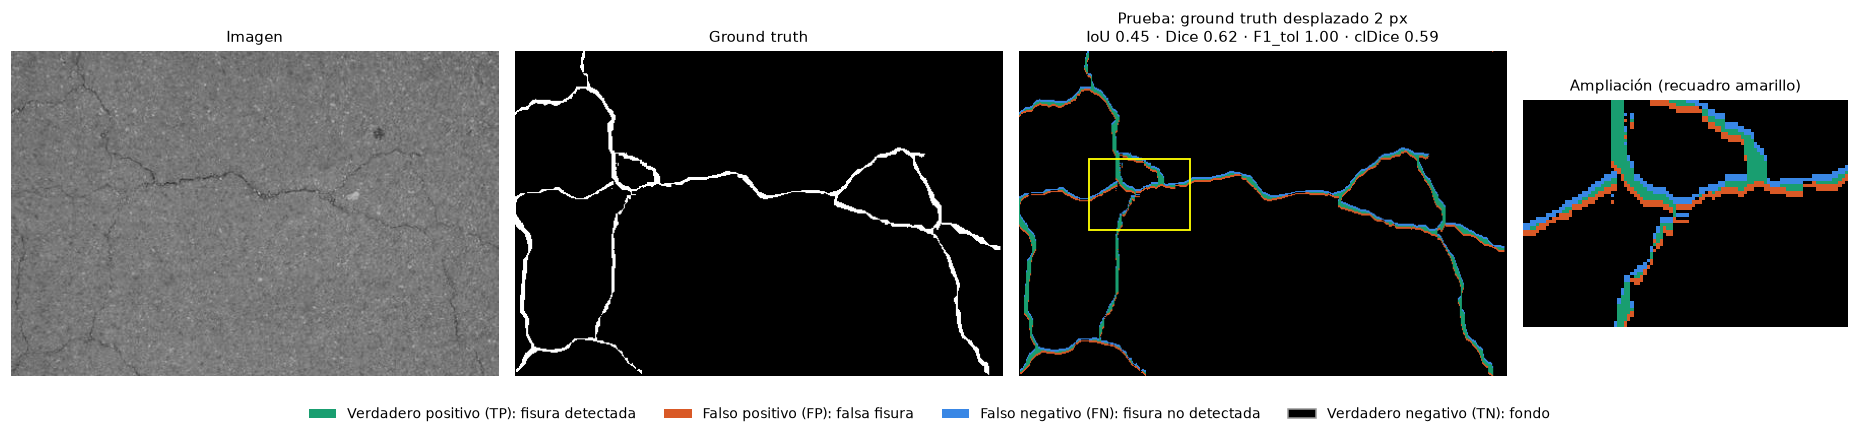

In [12]:
# Visualización de los mapas de errores

# Convención de colores del mapa de errores (paleta verificada para daltonismo)
CONVENCION_ERRORES = {
    "TP": ("#199e70", "Verdadero positivo (TP): fisura detectada"),
    "FP": ("#d95926", "Falso positivo (FP): falsa fisura"),
    "FN": ("#3987e5", "Falso negativo (FN): fisura no detectada"),
}


def superposicion_errores(S, G):
    """Imagen RGB del mapa de errores según CONVENCION_ERRORES (fondo correcto en negro)."""
    rgb = np.zeros(G.shape + (3,))
    for caso, mascara in {"TP": S & G, "FP": S & ~G, "FN": ~S & G}.items():
        rgb[mascara] = matplotlib.colors.to_rgb(CONVENCION_ERRORES[caso][0])
    return rgb


def leyenda_errores(fig):
    """Añade bajo la figura la leyenda con la convención de colores del mapa de errores."""
    marcas = [Patch(facecolor=color, edgecolor="none", label=texto)
              for color, texto in CONVENCION_ERRORES.values()]
    marcas.append(Patch(facecolor="black", edgecolor="#999999", label="Verdadero negativo (TN): fondo"))
    fig.legend(handles=marcas, loc="lower center", ncol=4, frameon=False, fontsize=9,
               bbox_to_anchor=(0.5, -0.06))


def mostrar_evaluacion(img, G, S, titulo):
    """Muestra imagen, ground truth, mapa de errores con sus métricas, una ampliación y la leyenda."""
    r = evaluar(S, G)
    errores = superposicion_errores(S, G)
    zona = recorte_centrado(G, alto=70, ancho=100)        # función de la sección 1.2
    fig, ejes = plt.subplots(1, 4, figsize=(17, 3.6), gridspec_kw={"width_ratios": [3, 3, 3, 2]})
    ejes[0].imshow(img, cmap="gray", vmin=0, vmax=255)
    ejes[0].set_title("Imagen")
    ejes[1].imshow(G, cmap="gray")
    ejes[1].set_title("Ground truth")
    ejes[2].imshow(errores)
    ejes[2].set_title(f'{titulo}\nIoU {r["IoU"]:.2f} · Dice {r["Dice"]:.2f} · '
                      f'F1_tol {r["F1_tol"]:.2f} · clDice {r["clDice"]:.2f}')
    ejes[2].add_patch(plt.Rectangle((zona[1].start, zona[0].start),
                                    zona[1].stop - zona[1].start, zona[0].stop - zona[0].start,
                                    fill=False, edgecolor="yellow", linewidth=1.2))
    ejes[3].imshow(errores[zona], interpolation="nearest")
    ejes[3].set_title("Ampliación (recuadro amarillo)")
    for eje in ejes:
        eje.axis("off")
    plt.tight_layout()
    leyenda_errores(fig)
    return fig


muestra = next(m for m in calibracion if m["id"] == "068")
fig = mostrar_evaluacion(muestra["img"], muestra["gt"], desplazar(muestra["gt"], 2),
                         "Prueba: ground truth desplazado 2 px")
fig.savefig(RUTA_RESULTADOS / "fig03_prueba_visualizador.png", bbox_inches="tight")
plt.show()

## 3. Segmentadores

### 3.1 Preprocesado

Los tres segmentadores parten del mismo preprocesado. Primero se suaviza la imagen $I$ con un filtro gaussiano, $I_\sigma = I * g_\sigma$ con $\sigma = 1$ px, y luego se aplica el realce *black-hat*, dual del Top Hat (Soille, 2003):

$$
B = (I_\sigma \bullet D_r) - I_\sigma
$$

donde $\bullet$ es el cierre morfológico y $D_r$ un disco de radio $r$. El cierre rellena las estructuras oscuras más estrechas que el disco, de modo que $B$ es alto en la fisura y casi nulo en el fondo. $r$ se calibra en la sección 3.5; aquí se usan valores provisionales. Se implementa con `cv2.morphologyEx(..., MORPH_BLACKHAT, ...)`, equivalente a `skimage.morphology.black_tophat` con el mismo disco pero mucho más rápido con radios grandes.

`eliminar_objetos_pequenos` es el post-procesado común: etiqueta los componentes conexos (vecindad 8), cuenta sus píxeles con `np.bincount` y conserva los de área $\ge A_{min}$.

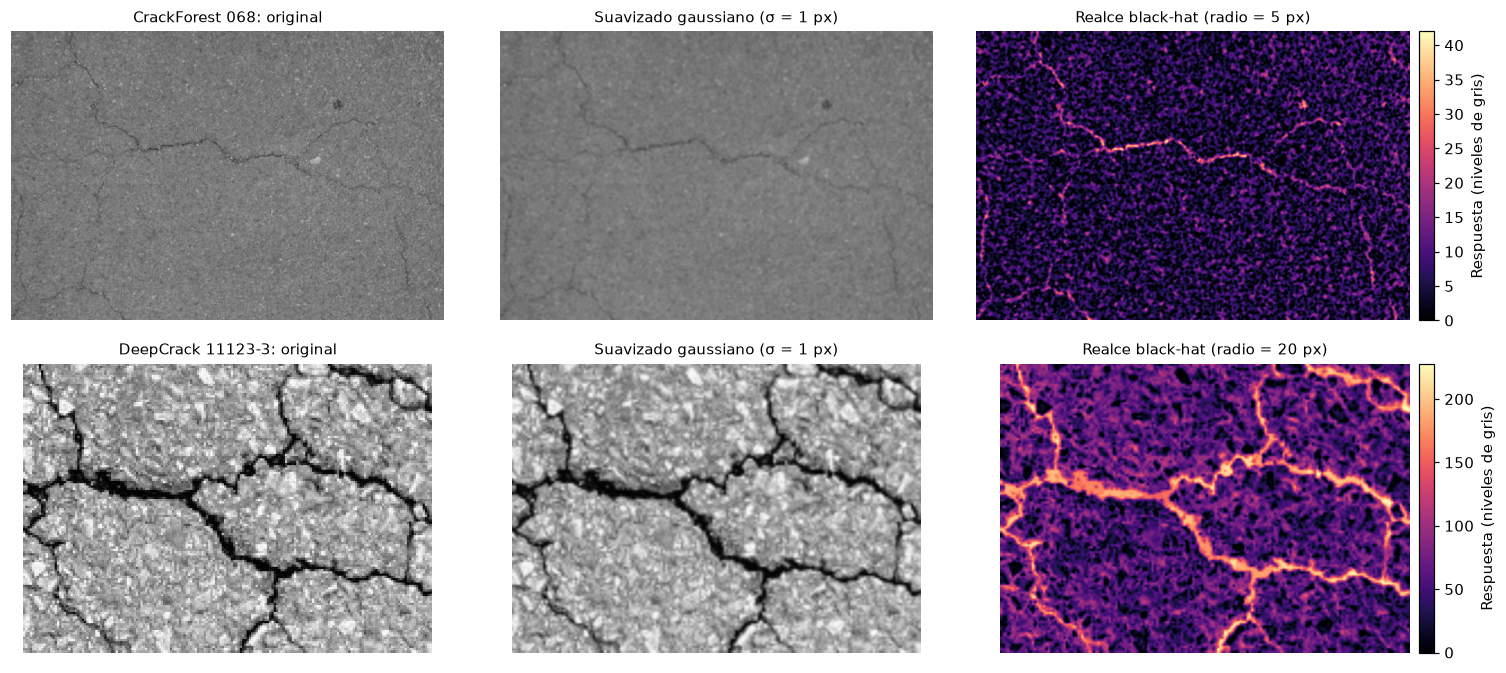

In [13]:
# Preprocesado de las imágenes para realzar las fisuras

# Valores provisionales solo para las demostraciones; los definitivos se calibran en la sección 4.6
RADIO_DEMO = {"CrackForest": 5, "DeepCrack": 20}
AREA_DEMO = 100
muestra_demo = next(m for m in calibracion if m["id"] == "068")


def preprocesar(img, radio):
    """Preprocesado común a los tres segmentadores.

    Parámetros
    ----------
    img : matriz uint8 en escala de grises.
    radio : int, radio (px) del elemento estructurante circular del black-hat.

    Devuelve
    --------
    suavizada : matriz uint8, imagen tras el filtro gaussiano.
    realce : matriz float, respuesta black-hat (alta en estructuras oscuras y finas).
    """
    suavizada = cv2.GaussianBlur(img, (0, 0), SIGMA_SUAVIZADO)
    # Black-hat = cierre - imagen. OpenCV da el mismo resultado que skimage.morphology.black_tophat
    # con el mismo elemento estructurante circular, pero es mucho más rápido con radios grandes.
    realce = cv2.morphologyEx(suavizada, cv2.MORPH_BLACKHAT, disk(radio).astype(np.uint8)).astype(float)
    return suavizada, realce


def eliminar_objetos_pequenos(mascara, area_minima):
    """Elimina los componentes conexos (vecindad 8) con menos de area_minima píxeles.

    Parámetros
    ----------
    mascara : matriz booleana.
    area_minima : int, área mínima (px) de los objetos que se conservan.

    Devuelve
    --------
    mascara_limpia : matriz booleana.
    """
    if area_minima <= 0 or not mascara.any():
        return mascara
    etiquetas, _ = ndimage.label(mascara, structure=np.ones((3, 3)))   # numera cada objeto
    areas = np.bincount(etiquetas.ravel())                             # píxeles de cada objeto
    conservar = areas >= area_minima
    conservar[0] = False                                               # la etiqueta 0 es el fondo
    return conservar[etiquetas]


# Demostración del preprocesado en una imagen de cada conjunto
demo_pre = [(muestra_demo, RADIO_DEMO["CrackForest"]),
            (next(m for m in calibracion if m["id"] == "11123-3"), RADIO_DEMO["DeepCrack"])]

fig, ejes = plt.subplots(2, 3, figsize=(14, 6.2))
for fila, (m, radio) in enumerate(demo_pre):
    suavizada, realce = preprocesar(m["img"], radio)
    ejes[fila, 0].imshow(m["img"], cmap="gray", vmin=0, vmax=255)
    ejes[fila, 0].set_title(f'{m["conjunto"]} {m["id"]}: original')
    ejes[fila, 1].imshow(suavizada, cmap="gray", vmin=0, vmax=255)
    ejes[fila, 1].set_title(f"Suavizado gaussiano (σ = {SIGMA_SUAVIZADO:g} px)")
    im = ejes[fila, 2].imshow(realce, cmap="magma")
    ejes[fila, 2].set_title(f"Realce black-hat (radio = {radio} px)")
    fig.colorbar(im, ax=ejes[fila, 2], fraction=0.046, pad=0.02, label="Respuesta (niveles de gris)")
for eje in ejes.ravel():
    eje.axis("off")
plt.tight_layout()
plt.savefig(RUTA_RESULTADOS / "fig04_preprocesado.png", bbox_inches="tight")
plt.show()

### 3.2 Segmentador 1: umbral global de Otsu (línea base)

Se elige el umbral $u^*$ que maximiza la varianza entre las clases del histograma del realce $B$ (Otsu, 1979):

$$
u^* = \arg\max_u \; \omega_0(u)\,\omega_1(u)\,\big[\mu_0(u) - \mu_1(u)\big]^2
\qquad
S = \big\{p : B(p) > u^*\big\}
$$

donde $\omega_k$ y $\mu_k$ son la proporción y la media de cada clase. Después se eliminan los objetos de área menor que $A_{min}$. La figura muestra el histograma con el umbral, la máscara antes y después de la limpieza y el mapa de errores (parámetros provisionales).

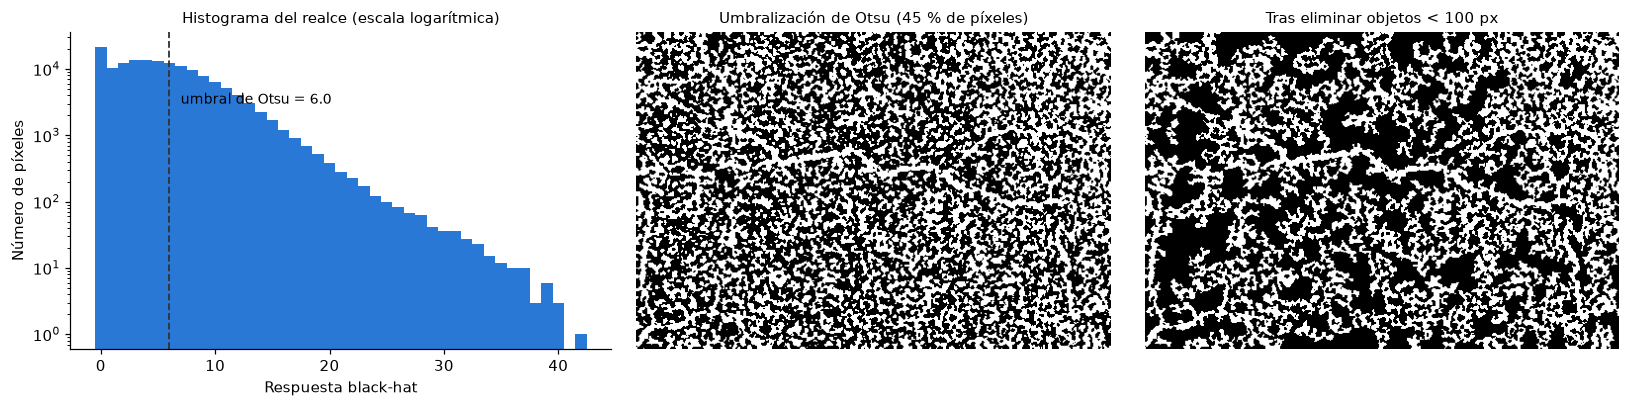

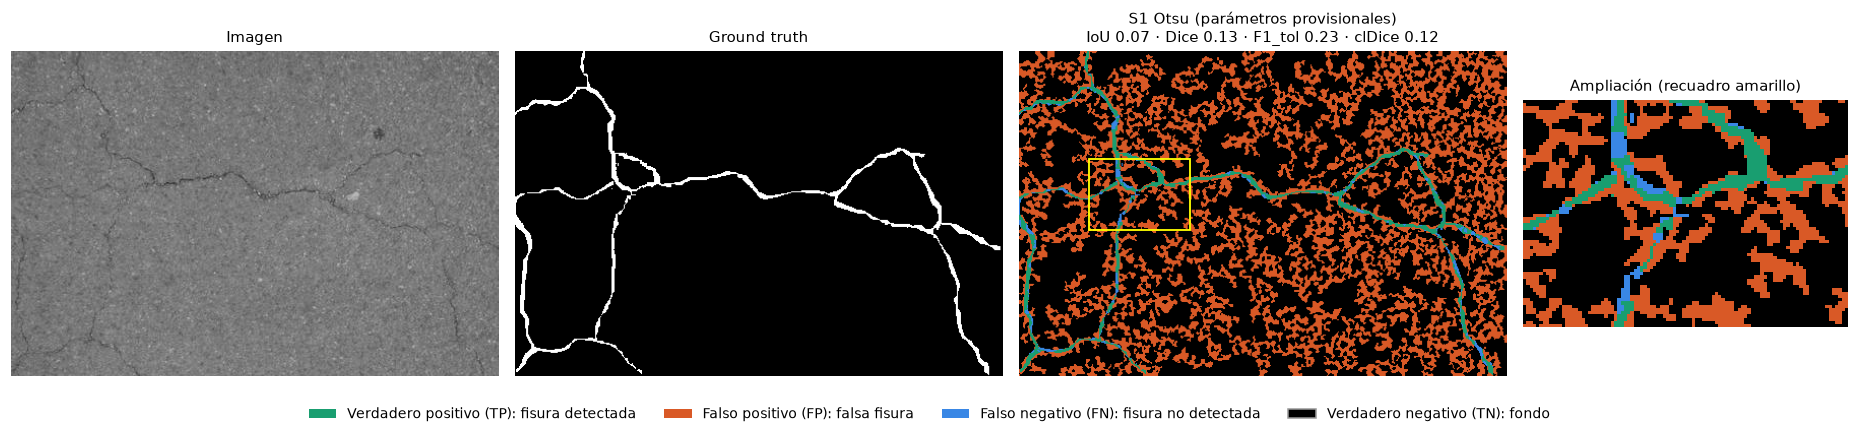

In [14]:
# Segmentador 1: umbral global de Otsu sobre el realce black-hat

def segmentar_otsu(realce, area_minima):
    """Segmentador 1 (línea base): umbral global de Otsu sobre el realce black-hat.

    Parámetros
    ----------
    realce : matriz float, respuesta black-hat (salida de preprocesar).
    area_minima : int, área mínima (px) de los objetos que se conservan.

    Devuelve
    --------
    mascara : matriz booleana, True en los píxeles clasificados como fisura.
    pasos : diccionario con los resultados intermedios (umbral y máscara sin limpiar).
    """
    umbral = threshold_otsu(realce)
    binaria = realce > umbral
    mascara = eliminar_objetos_pequenos(binaria, area_minima)
    return mascara, {"umbral": umbral, "binaria": binaria}


# Pasos principales sobre la imagen de demostración (parámetros provisionales)
_, realce_demo = preprocesar(muestra_demo["img"], RADIO_DEMO["CrackForest"])
S_otsu, pasos_otsu = segmentar_otsu(realce_demo, AREA_DEMO)

fig, ejes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.1, 1, 1]})
ejes[0].hist(realce_demo.ravel(), bins=np.arange(realce_demo.max() + 2) - 0.5, color="#2a78d6", log=True)
ejes[0].axvline(pasos_otsu["umbral"], color="#333333", linestyle="--", linewidth=1.2)
ejes[0].text(pasos_otsu["umbral"] + 1, 3e3, f'umbral de Otsu = {pasos_otsu["umbral"]:.1f}', fontsize=9)
ejes[0].set_title("Histograma del realce (escala logarítmica)")
ejes[0].set_xlabel("Respuesta black-hat")
ejes[0].set_ylabel("Número de píxeles")
ejes[0].spines[["top", "right"]].set_visible(False)
ejes[1].imshow(pasos_otsu["binaria"], cmap="gray")
ejes[1].set_title(f'Umbralización de Otsu ({100 * pasos_otsu["binaria"].mean():.0f} % de píxeles)')
ejes[2].imshow(S_otsu, cmap="gray")
ejes[2].set_title(f"Tras eliminar objetos < {AREA_DEMO} px")
for eje in ejes[1:]:
    eje.axis("off")
plt.tight_layout()
plt.savefig(RUTA_RESULTADOS / "fig05_otsu_pasos.png", bbox_inches="tight")
plt.show()

fig = mostrar_evaluacion(muestra_demo["img"], muestra_demo["gt"], S_otsu, "S1 Otsu (parámetros provisionales)")
plt.show()

### 3.3 Segmentador 2: crecimiento de regiones a partir de semillas (implementación propia)

Con $P_q(B)$ el percentil $q$ del realce de la imagen:

$$
\text{Semillas} = \{p : B(p) \ge P_{p_{semilla}}(B)\}
\qquad
\text{Pertenencia: } q \in R \iff q \in N_8(R) \;\wedge\; B(q) \ge P_{p_{crecimiento}}(B)
$$

La región $R$ empieza en las semillas y crece con una búsqueda en anchura: una cola (`deque`) guarda los píxeles pendientes y, para cada uno, se examinan sus 8 vecinos; se añaden los que cumplen la pertenencia y aún no forman parte de $R$. El proceso termina cuando la cola se vacía, es decir, cuando ningún vecino cumple la condición. La matriz `iteracion` guarda en qué paso se incorporó cada píxel (0 = semilla) y permite visualizar la evolución del crecimiento. Por último se eliminan los objetos menores que $A_{min}$.

La figura muestra los cuatro pasos: semillas, píxeles admisibles, iteración de incorporación y región final.

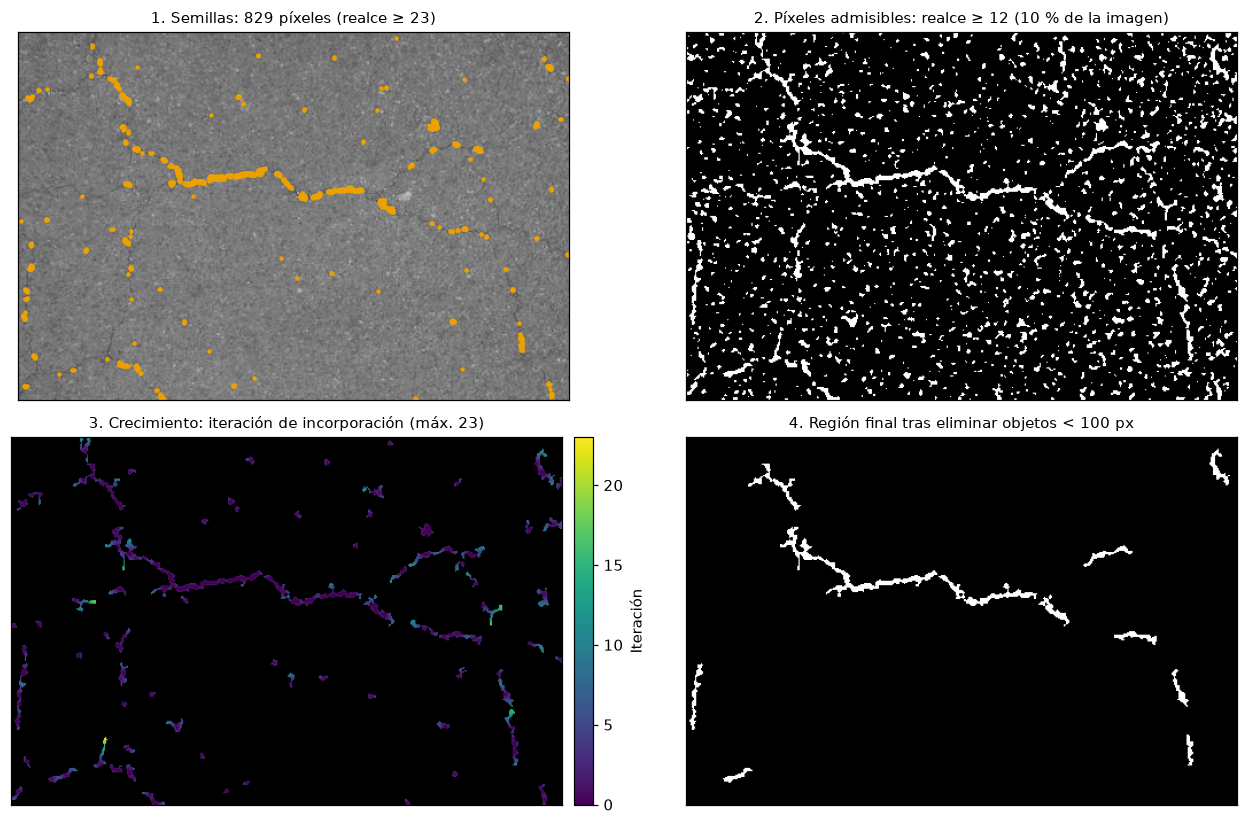

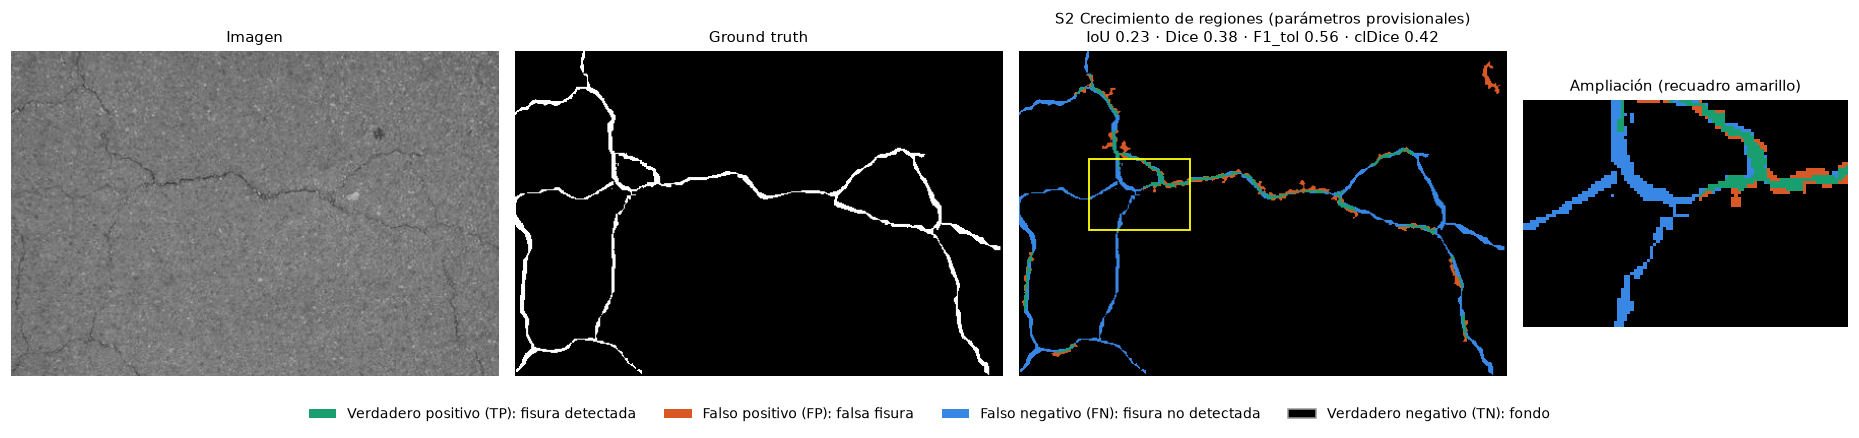

In [15]:
# Segmentador 2: crecimiento de regiones a partir de semillas (implementación propia)

VECINOS_8 = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]


def segmentar_crecimiento_regiones(realce, p_semilla, p_crecimiento, area_minima):
    """Segmentador 2: crecimiento de regiones a partir de semillas (implementación propia).

    Parámetros
    ----------
    realce : matriz float, respuesta black-hat (salida de preprocesar).
    p_semilla : float, percentil del realce a partir del cual un píxel es semilla (p. ej. 99.5).
    p_crecimiento : float, percentil del realce que debe superar un píxel para unirse a la región.
    area_minima : int, área mínima (px) de los objetos que se conservan.

    Devuelve
    --------
    mascara : matriz booleana, True en los píxeles clasificados como fisura.
    pasos : diccionario con semillas, píxeles admisibles, iteración de incorporación y umbrales.
    """
    umbral_semilla = np.percentile(realce, p_semilla)
    umbral_crecimiento = np.percentile(realce, p_crecimiento)
    admisible = realce >= umbral_crecimiento            # función de pertenencia: True si cumple el criterio
    alto, ancho = realce.shape

    # iteracion[f, c] = paso en que el píxel se incorporó a la región (-1 si nunca se incorporó)
    iteracion = np.full(realce.shape, -1, dtype=int)
    cola = deque()
    semillas = realce >= umbral_semilla
    for f, c in zip(*np.nonzero(semillas)):
        iteracion[f, c] = 0
        cola.append((f, c))

    # Crecimiento: se examinan los 8 vecinos de cada píxel de la región (búsqueda en anchura)
    while cola:
        f, c = cola.popleft()
        for df, dc in VECINOS_8:
            nf, nc = f + df, c + dc
            if 0 <= nf < alto and 0 <= nc < ancho and admisible[nf, nc] and iteracion[nf, nc] < 0:
                iteracion[nf, nc] = iteracion[f, c] + 1
                cola.append((nf, nc))

    region = iteracion >= 0
    mascara = eliminar_objetos_pequenos(region, area_minima)
    pasos = {"semillas": semillas, "admisible": admisible, "iteracion": iteracion, "region": region,
             "umbral_semilla": umbral_semilla, "umbral_crecimiento": umbral_crecimiento}
    return mascara, pasos


# Pasos principales sobre la imagen de demostración (parámetros provisionales)
_, realce_demo = preprocesar(muestra_demo["img"], RADIO_DEMO["CrackForest"])
S_rc, pasos_rc = segmentar_crecimiento_regiones(realce_demo, p_semilla=99.5, p_crecimiento=90,
                                                area_minima=AREA_DEMO)

fig, ejes = plt.subplots(2, 2, figsize=(12, 7.6))
ejes[0, 0].imshow(muestra_demo["img"], cmap="gray", vmin=0, vmax=255)
filas_s, columnas_s = np.nonzero(pasos_rc["semillas"])
ejes[0, 0].scatter(columnas_s, filas_s, s=4, color="#eda100")
ejes[0, 0].set_title(f'1. Semillas: {pasos_rc["semillas"].sum()} píxeles '
                     f'(realce ≥ {pasos_rc["umbral_semilla"]:.0f})')
ejes[0, 1].imshow(pasos_rc["admisible"], cmap="gray")
ejes[0, 1].set_title(f'2. Píxeles admisibles: realce ≥ {pasos_rc["umbral_crecimiento"]:.0f} '
                     f'({100 * pasos_rc["admisible"].mean():.0f} % de la imagen)')
iteracion_visible = np.ma.masked_less(pasos_rc["iteracion"], 0)       # oculta los píxeles no incorporados
im = ejes[1, 0].imshow(iteracion_visible, cmap="viridis")
ejes[1, 0].set_facecolor("black")
ejes[1, 0].set_title(f'3. Crecimiento: iteración de incorporación (máx. {pasos_rc["iteracion"].max()})')
fig.colorbar(im, ax=ejes[1, 0], fraction=0.046, pad=0.02, label="Iteración")
ejes[1, 1].imshow(S_rc, cmap="gray")
ejes[1, 1].set_title(f"4. Región final tras eliminar objetos < {AREA_DEMO} px")
for eje in ejes.ravel():
    eje.set_xticks([])
    eje.set_yticks([])
plt.tight_layout()
plt.savefig(RUTA_RESULTADOS / "fig06_crecimiento_pasos.png", bbox_inches="tight")
plt.show()

fig = mostrar_evaluacion(muestra_demo["img"], muestra_demo["gt"], S_rc,
                         "S2 Crecimiento de regiones (parámetros provisionales)")
plt.show()

### 3.4 Segmentador 3: transformada Watershed controlada por marcadores

1. **Relieve:** magnitud del gradiente de Sobel de la imagen suavizada, $\lvert\nabla I_\sigma\rvert$.
2. **Marcadores:** fondo seguro $M_1 = \{p : B(p) \le P_{p_{fondo}}(B)\}$ y fisura segura $M_2 = \{p : B(p) \ge P_{p_{fisura}}(B)\}$. El resto es zona dudosa, sin marcador.
3. **Inundación:** `watershed` inunda el relieve desde los marcadores; cada píxel dudoso se asigna a la cuenca que lo alcanza primero, y las líneas divisorias quedan en las crestas del gradiente.
4. **Resultado:** $S$ = cuencas de fisura, sin los objetos menores que $A_{min}$.

La figura muestra el gradiente, los marcadores (fondo en azul, fisura en amarillo), las líneas divisorias y la máscara final.

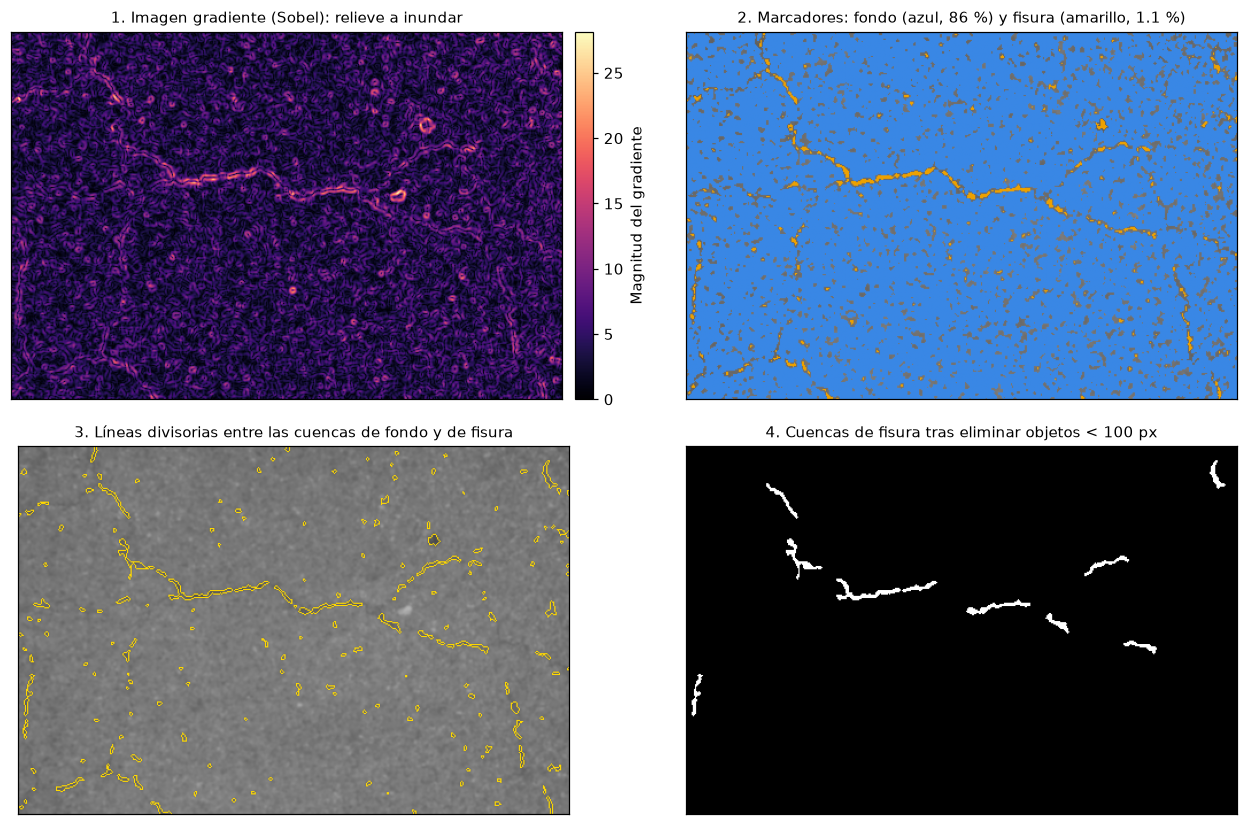

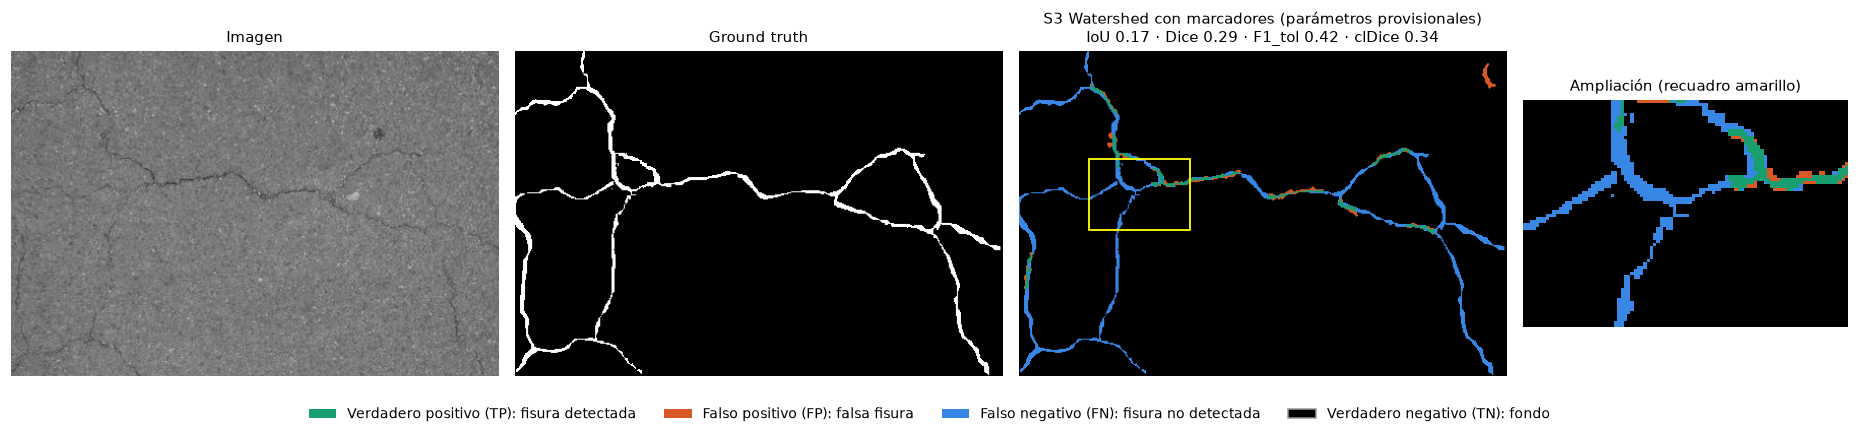

In [16]:
# Segmentador 3: Watershed controlada por marcadores

def segmentar_watershed(suavizada, realce, p_fondo, p_fisura, area_minima):
    """Segmentador 3: transformada Watershed controlada por marcadores.

    Parámetros
    ----------
    suavizada : matriz uint8, imagen suavizada (salida de preprocesar).
    realce : matriz float, respuesta black-hat (salida de preprocesar).
    p_fondo : float, percentil del realce por debajo del cual un píxel es marcador de fondo.
    p_fisura : float, percentil del realce por encima del cual un píxel es marcador de fisura.
    area_minima : int, área mínima (px) de los objetos que se conservan.

    Devuelve
    --------
    mascara : matriz booleana, True en los píxeles clasificados como fisura.
    pasos : diccionario con el gradiente, los marcadores y las etiquetas resultantes.
    """
    gradiente = sobel(suavizada.astype(float))                 # relieve topográfico a inundar
    marcadores = np.zeros(realce.shape, dtype=int)             # 0 = zona dudosa (sin marcador)
    marcadores[realce <= np.percentile(realce, p_fondo)] = 1   # 1 = fondo seguro
    marcadores[realce >= np.percentile(realce, p_fisura)] = 2  # 2 = fisura segura
    etiquetas = watershed(gradiente, marcadores)               # inundación desde los marcadores
    mascara = eliminar_objetos_pequenos(etiquetas == 2, area_minima)
    return mascara, {"gradiente": gradiente, "marcadores": marcadores, "etiquetas": etiquetas}


# --- Pasos principales sobre la imagen de demostración (parámetros provisionales) ---
suavizada_demo, realce_demo = preprocesar(muestra_demo["img"], RADIO_DEMO["CrackForest"])
S_ws, pasos_ws = segmentar_watershed(suavizada_demo, realce_demo, p_fondo=85, p_fisura=99.0,
                                     area_minima=AREA_DEMO)

fig, ejes = plt.subplots(2, 2, figsize=(12, 7.6))

# 1. Gradiente
im = ejes[0, 0].imshow(pasos_ws["gradiente"], cmap="magma")
ejes[0, 0].set_title("1. Imagen gradiente (Sobel): relieve a inundar")
fig.colorbar(im, ax=ejes[0, 0], fraction=0.046, pad=0.02, label="Magnitud del gradiente")

# 2. Marcadores sobre la imagen suavizada
vista_marcadores = np.dstack([suavizada_demo / 255.0] * 3)
vista_marcadores[pasos_ws["marcadores"] == 1] = matplotlib.colors.to_rgb("#3987e5")
vista_marcadores[pasos_ws["marcadores"] == 2] = matplotlib.colors.to_rgb("#eda100")
ejes[0, 1].imshow(vista_marcadores)
ejes[0, 1].set_title(f'2. Marcadores: fondo (azul, {100 * (pasos_ws["marcadores"] == 1).mean():.0f} %) '
                     f'y fisura (amarillo, {100 * (pasos_ws["marcadores"] == 2).mean():.1f} %)')

# 3. Líneas divisorias: borde interior de las cuencas de fisura
vista_lineas = np.dstack([suavizada_demo / 255.0] * 3)
lineas = find_boundaries(pasos_ws["etiquetas"], mode="inner") & (pasos_ws["etiquetas"] == 2)
vista_lineas[lineas] = (1.0, 0.85, 0.0)
ejes[1, 0].imshow(vista_lineas)
ejes[1, 0].set_title("3. Líneas divisorias entre las cuencas de fondo y de fisura")

# 4. Resultado final
ejes[1, 1].imshow(S_ws, cmap="gray")
ejes[1, 1].set_title(f"4. Cuencas de fisura tras eliminar objetos < {AREA_DEMO} px")

for eje in ejes.ravel():
    eje.set_xticks([])
    eje.set_yticks([])
plt.tight_layout()
plt.savefig(RUTA_RESULTADOS / "fig07_watershed_pasos.png", bbox_inches="tight")
plt.show()

fig = mostrar_evaluacion(muestra_demo["img"], muestra_demo["gt"], S_ws,
                         "S3 Watershed con marcadores (parámetros provisionales)")
plt.show()

### 3.5 Calibración de parámetros

**Las imágenes de evaluación no intervienen en esta sección.** Para cada conjunto y método se evalúan todas las combinaciones $\theta$ de la rejilla sobre sus 20 imágenes de calibración y se elige

$$
\theta^* = \arg\max_\theta \; \frac{1}{20}\sum_{i=1}^{20} F1_\tau\big(S_i(\theta), G_i\big)
$$

La rejilla tiene 198 combinaciones (99 por conjunto); el radio del *black-hat* depende del conjunto. El preprocesado solo depende del radio, así que se calcula una vez por radio y se reutiliza. El diccionario `SEGMENTADORES` da a los tres métodos una interfaz común, y `segmentar_con_los_tres` aplica los parámetros calibrados en las secciones 4 y 5.

La búsqueda tarda unos minutos, por lo que se guarda en `calibracion_rejilla.csv` y se carga si existe. Para repetirla, `RECALIBRAR = True`.

In [17]:
# Calibración de parámetros (SOLO CON LAS IMÁGENES DE CALIBRACIÓN)

RECALIBRAR = False      # True: repetir la búsqueda aunque exista el archivo guardado
ARCHIVO_CALIBRACION = RUTA_RESULTADOS / "calibracion_rejilla.csv"

# --- Valores candidatos de cada parámetro ---
RADIOS = {"CrackForest": [3, 5, 7], "DeepCrack": [10, 20, 30]}
REJILLAS = {
    "S1 Otsu": {"area_minima": [0, 30, 100]},
    "S2 Crecimiento de regiones": {"p_semilla": [99.0, 99.5, 99.8],
                                   "p_crecimiento": [85, 90, 94],
                                   "area_minima": [30, 100]},
    "S3 Watershed": {"p_fondo": [85, 90, 95],
                     "p_fisura": [98.0, 99.0],
                     "area_minima": [30, 100]},
}

# --- Interfaz común: cada segmentador recibe (suavizada, realce, parámetros) y devuelve la máscara ---
SEGMENTADORES = {
    "S1 Otsu": lambda suav, realce, **p: segmentar_otsu(realce, **p)[0],
    "S2 Crecimiento de regiones": lambda suav, realce, **p: segmentar_crecimiento_regiones(realce, **p)[0],
    "S3 Watershed": lambda suav, realce, **p: segmentar_watershed(suav, realce, **p)[0],
}

METODOS = list(SEGMENTADORES.keys())

def segmentar_con_los_tres(img, perfil):
    """Aplica S1, S2 y S3 con los parámetros calibrados de un perfil ("CrackForest" o "DeepCrack").

    El preprocesado se calcula una sola vez por radio y su tiempo se suma al del primer
    método que lo usa. Se emplea en las secciones 4 y 5, una vez definido PARAMETROS.

    Devuelve
    --------
    mascaras : diccionario {método: máscara booleana}.
    tiempos : diccionario {método: tiempo en segundos, incluido el preprocesado}.
    """
    mascaras, tiempos, cache = {}, {}, {}
    for metodo in METODOS:
        parametros = dict(PARAMETROS[(perfil, metodo)])
        radio = parametros.pop("radio")
        t0 = time.perf_counter()
        if radio not in cache:
            cache[radio] = preprocesar(img, radio)
        mascaras[metodo] = SEGMENTADORES[metodo](*cache[radio], **parametros)
        tiempos[metodo] = time.perf_counter() - t0
    return mascaras, tiempos

def calibrar():
    """Evalúa todas las combinaciones de parámetros sobre las imágenes de calibración.

    Devuelve
    --------
    resultados : DataFrame con una fila por combinación (conjunto, método, parámetros,
        F1_tol medio y Dice medio).
    """
    filas = []
    inicio = time.time()
    for conjunto, radios in RADIOS.items():
        muestras = [m for m in calibracion if m["conjunto"] == conjunto]
        for radio in radios:
            # El preprocesado depende solo del radio: se calcula una vez y se reutiliza
            preprocesadas = [(m["gt"], *preprocesar(m["img"], radio)) for m in muestras]
            for metodo, rejilla in REJILLAS.items():
                nombres = list(rejilla.keys())
                for valores in itertools.product(*rejilla.values()):
                    parametros = dict(zip(nombres, valores))
                    f1, dice = [], []
                    for gt, suavizada, realce in preprocesadas:
                        S = SEGMENTADORES[metodo](suavizada, realce, **parametros)
                        f1.append(f1_con_tolerancia(S, gt)["F1_tol"])
                        dice.append(metricas_solapamiento(S, gt)["Dice"])
                    filas.append({"Conjunto": conjunto, "Método": metodo, "radio": radio, **parametros,
                                  "F1_tol": np.mean(f1), "Dice": np.mean(dice)})
            print(f"  {conjunto}, radio {radio:2d} px: completado ({time.time() - inicio:.0f} s)")
    return pd.DataFrame(filas)


if ARCHIVO_CALIBRACION.exists() and not RECALIBRAR:
    rejilla_resultados = pd.read_csv(ARCHIVO_CALIBRACION)
    print(f"Calibración cargada de {ARCHIVO_CALIBRACION} ({len(rejilla_resultados)} combinaciones).")
else:
    print("Calibrando (búsqueda en rejilla sobre las 40 imágenes de calibración)...")
    rejilla_resultados = calibrar()
    rejilla_resultados.to_csv(ARCHIVO_CALIBRACION, index=False)
    print(f"Guardada en {ARCHIVO_CALIBRACION} ({len(rejilla_resultados)} combinaciones).")

# --- Selección: para cada conjunto y método, la combinación con mayor F1_tol medio ---
mejores = rejilla_resultados.loc[rejilla_resultados.groupby(["Conjunto", "Método"])["F1_tol"].idxmax()]

PARAMETROS = {}
for _, fila in mejores.iterrows():
    nombres = ["radio"] + list(REJILLAS[fila["Método"]].keys())
    PARAMETROS[(fila["Conjunto"], fila["Método"])] = {
        n: (int(fila[n]) if n in ("radio", "area_minima") else float(fila[n])) for n in nombres
    }

Calibrando (búsqueda en rejilla sobre las 40 imágenes de calibración)...
  CrackForest, radio  3 px: completado (27 s)
  CrackForest, radio  5 px: completado (54 s)
  CrackForest, radio  7 px: completado (83 s)
  DeepCrack, radio 10 px: completado (122 s)
  DeepCrack, radio 20 px: completado (164 s)
  DeepCrack, radio 30 px: completado (207 s)
Guardada en resultados_act2\calibracion_rejilla.csv (198 combinaciones).


La siguiente celda muestra los parámetros elegidos con su $F1_\tau$ y su Dice de calibración (`parametros_seleccionados.csv`). Para valorar si el óptimo es estable, calcula también la diferencia entre la mejor combinación y la quinta mejor:

$$
\Delta_5 = F1_\tau(\theta_{(1)}) - F1_\tau(\theta_{(5)})
$$

Un $\Delta_5$ pequeño indica que varias combinaciones cercanas rinden casi igual, de modo que el resultado no depende de un ajuste fino.

In [18]:
# Parámetros seleccionados y métricas de calibración

tabla_parametros = pd.DataFrame([
    {"Conjunto": c, "Método": met,
     "Parámetros": ", ".join(f"{k} = {v:g}" for k, v in p.items()),
     "F1_tol (calibración)": fila["F1_tol"], "Dice (calibración)": fila["Dice"]}
    for (c, met), p in PARAMETROS.items()
    for _, fila in mejores[(mejores["Conjunto"] == c) & (mejores["Método"] == met)].iterrows()
]).set_index(["Conjunto", "Método"]).round(3)
tabla_parametros.to_csv(RUTA_RESULTADOS / "parametros_seleccionados.csv")
print(tabla_parametros.to_string())

# --- Robustez: diferencia entre la mejor combinación y la quinta mejor ---
print("\nDiferencia de F1_tol entre la mejor combinación y la quinta mejor:")
for (c, met), grupo in rejilla_resultados.groupby(["Conjunto", "Método"]):
    f1_ordenado = grupo["F1_tol"].sort_values(ascending=False).values
    print(f"  {c:11s} {met:28s} {f1_ordenado[0] - f1_ordenado[min(4, len(f1_ordenado) - 1)]:.3f}")

                                                                                                 Parámetros  F1_tol (calibración)  Dice (calibración)
Conjunto    Método                                                                                                                                   
CrackForest S1 Otsu                                                            radio = 3, area_minima = 100                 0.274               0.171
            S2 Crecimiento de regiones   radio = 5, p_semilla = 99.5, p_crecimiento = 90, area_minima = 100                 0.739               0.521
            S3 Watershed                           radio = 5, p_fondo = 95, p_fisura = 98, area_minima = 30                 0.734               0.523
DeepCrack   S1 Otsu                                                           radio = 10, area_minima = 100                 0.506               0.424
            S2 Crecimiento de regiones  radio = 20, p_semilla = 99.5, p_crecimiento = 94, area_minim

## 4. Evaluación comparativa

### 4.1 Aplicación a las imágenes de evaluación

Cada uno de los tres segmentadores se aplica, con los parámetros fijados en la sección 3.5, a las 332 imágenes de evaluación, y cada máscara se evalúa con `evaluar`. El tiempo de cada método incluye el preprocesado. Se obtiene una fila por imagen y método (996 filas), guardada en `resultados_evaluacion.csv`. Si el archivo existe y corresponde exactamente a las imágenes de evaluación actuales, se carga (`REEVALUAR = False`); si no, se recalcula, lo que tarda menos de 2 minutos.

In [19]:
# Evaluación de los segmentadores calibrados sobre las imágenes de evaluación

REEVALUAR = False       # True: repetir la evaluación aunque exista el archivo guardado
ARCHIVO_EVALUACION = RUTA_RESULTADOS / "resultados_evaluacion.csv"


def evaluar_conjunto(muestras):
    """Aplica los tres segmentadores calibrados a cada imagen y la evalúa con el evaluador propio.

    Parámetros
    ----------
    muestras : lista de diccionarios con las claves "conjunto", "id", "img" y "gt".

    Devuelve
    --------
    resultados : DataFrame con una fila por imagen y método (métricas y tiempo de segmentación).
    """
    filas = []
    inicio = time.time()
    for i, m in enumerate(muestras, start=1):
        mascaras, tiempos = segmentar_con_los_tres(m["img"], m["conjunto"])
        for metodo, S in mascaras.items():
            filas.append({"Conjunto": m["conjunto"], "Imagen": m["id"], "Método": metodo,
                          **evaluar(S, m["gt"]), "Tiempo (s)": tiempos[metodo]})
        if i % 50 == 0 or i == len(muestras):
            print(f"  {i}/{len(muestras)} imágenes evaluadas ({time.time() - inicio:.0f} s)")
    return pd.DataFrame(filas)


# Si el archivo guardado no corresponde exactamente a las imágenes de evaluación actuales, se recalcula
imagenes_actuales = {(m["conjunto"], m["id"]) for m in evaluacion}
if ARCHIVO_EVALUACION.exists() and not REEVALUAR:
    resultados = pd.read_csv(ARCHIVO_EVALUACION, dtype={"Imagen": str})
    if set(zip(resultados["Conjunto"], resultados["Imagen"])) != imagenes_actuales:
        print("El archivo guardado no coincide con las imágenes de evaluación actuales: se recalcula.")
        REEVALUAR = True
    else:
        print(f"Resultados cargados de {ARCHIVO_EVALUACION} ({len(resultados)} filas).")
if not ARCHIVO_EVALUACION.exists() or REEVALUAR:
    print(f"Evaluando {len(evaluacion)} imágenes x {len(METODOS)} métodos...")
    resultados = evaluar_conjunto(evaluacion)
    resultados.to_csv(ARCHIVO_EVALUACION, index=False)
    print(f"Guardados en {ARCHIVO_EVALUACION} ({len(resultados)} filas).")

Evaluando 332 imágenes x 3 métodos...
  50/332 imágenes evaluadas (6 s)
  100/332 imágenes evaluadas (13 s)
  150/332 imágenes evaluadas (22 s)
  200/332 imágenes evaluadas (32 s)
  250/332 imágenes evaluadas (42 s)
  300/332 imágenes evaluadas (51 s)
  332/332 imágenes evaluadas (57 s)
Guardados en resultados_act2\resultados_evaluacion.csv (996 filas).


La siguiente celda resume los resultados por conjunto y método como media ± desviación típica de cada métrica, junto con el tiempo medio por imagen (`tabla_resumen_evaluacion.csv`). Los conjuntos se resumen por separado porque el valor de las métricas depende del grosor de la fisura (secciones 1.5 y 2.5)..

In [20]:
# Resumen de métricas sobre las imágenes de evaluación

METRICAS = ["IoU", "Dice", "Precision", "Sensibilidad", "F1_tol", "clDice"]

agrupado = resultados.groupby(["Conjunto", "Método"])
media = agrupado[METRICAS].mean()
desviacion = agrupado[METRICAS].std()

# Tabla para mostrar: "media ± desviación típica" con tres decimales
formato = lambda tabla: tabla.apply(lambda columna: columna.map("{:.3f}".format))
tabla_resumen = formato(media) + " ± " + formato(desviacion)
tabla_resumen.insert(0, "n", agrupado.size())
tabla_resumen["Tiempo (s)"] = agrupado["Tiempo (s)"].mean().map("{:.2f}".format)
tabla_resumen.to_csv(RUTA_RESULTADOS / "tabla_resumen_evaluacion.csv")

pd.set_option("display.width", 200)
print("Media ± desviación típica sobre las imágenes de evaluación:\n")
print(tabla_resumen.to_string())

Media ± desviación típica sobre las imágenes de evaluación:

                                          n            IoU           Dice      Precision   Sensibilidad         F1_tol         clDice Tiempo (s)
Conjunto    Método                                                                                                                              
CrackForest S1 Otsu                      95  0.142 ± 0.126  0.230 ± 0.171  0.163 ± 0.170  0.747 ± 0.140  0.339 ± 0.224  0.241 ± 0.194       0.00
            S2 Crecimiento de regiones   95  0.376 ± 0.122  0.534 ± 0.140  0.488 ± 0.139  0.634 ± 0.203  0.744 ± 0.173  0.616 ± 0.172       0.03
            S3 Watershed                 95  0.353 ± 0.140  0.506 ± 0.161  0.550 ± 0.163  0.500 ± 0.206  0.699 ± 0.192  0.593 ± 0.193       0.04
DeepCrack   S1 Otsu                     237  0.438 ± 0.286  0.552 ± 0.291  0.565 ± 0.356  0.779 ± 0.223  0.632 ± 0.308  0.573 ± 0.332       0.01
            S2 Crecimiento de regiones  237  0.618 ± 0.192  0.745 ± 0

### 4.2 Distribución de las métricas por imagen

La media puede ocultar comportamientos distintos. Los diagramas de caja muestran la distribución de cada métrica sobre las imágenes de evaluación:
- la **caja** abarca el 50 % central de las imágenes;
- la **línea** es la mediana y el **rombo** la media;
- los **puntos** aislados son imágenes atípicas.

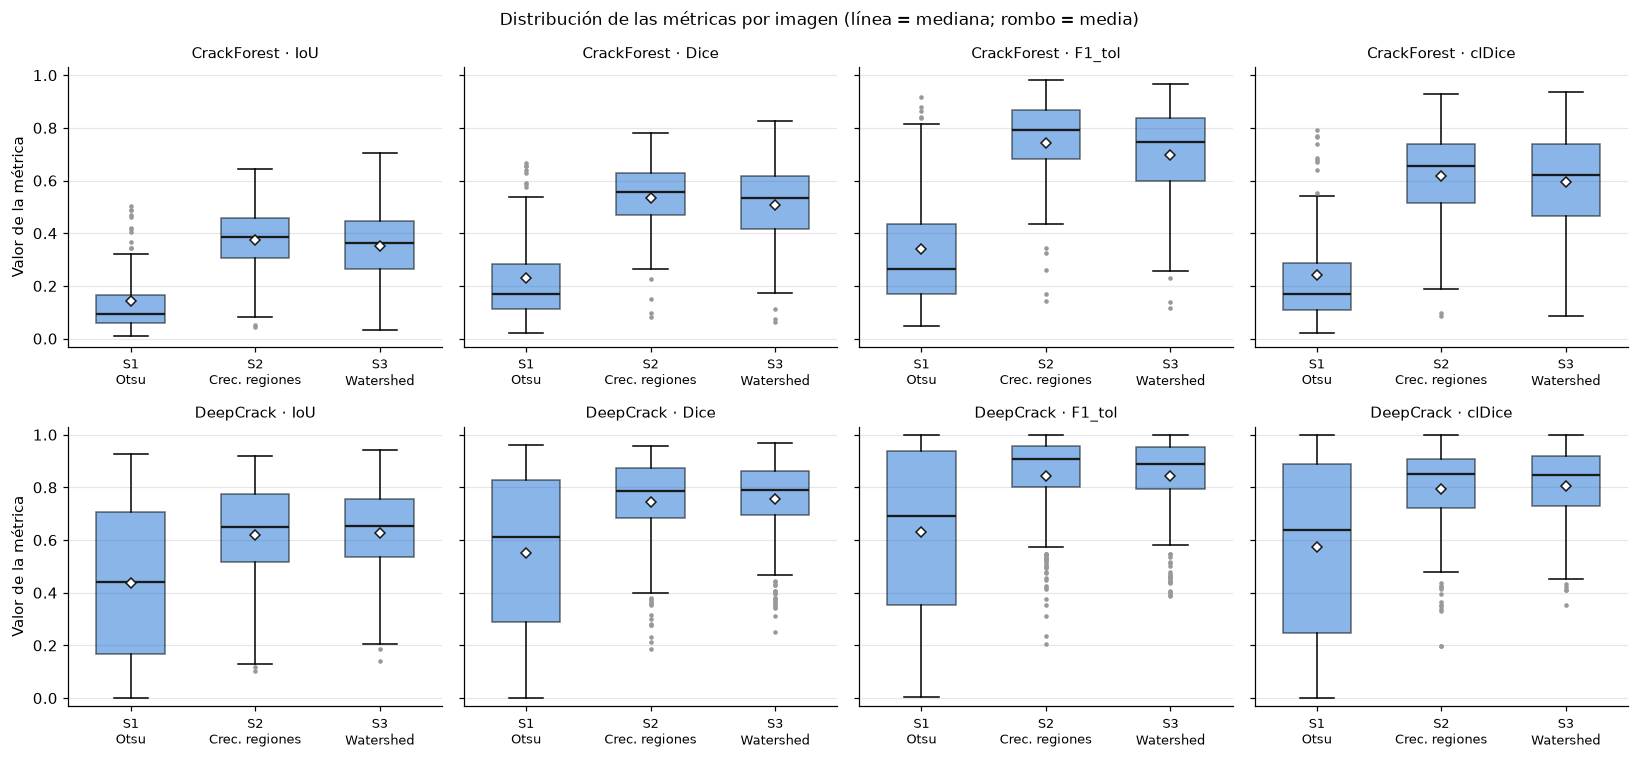

In [21]:
# Diagramas de caja de las métricas sobre las imágenes de evaluación

METRICAS_GRAFICO = ["IoU", "Dice", "F1_tol", "clDice"]
ETIQUETAS_METODO = {"S1 Otsu": "S1\nOtsu", "S2 Crecimiento de regiones": "S2\nCrec. regiones",
                    "S3 Watershed": "S3\nWatershed"}
COLOR_CAJAS = "#2a78d6"

fig, ejes = plt.subplots(2, 4, figsize=(15, 7), sharey=True)
for fila, conjunto in enumerate(["CrackForest", "DeepCrack"]):
    datos_conjunto = resultados[resultados["Conjunto"] == conjunto]
    for col, metrica in enumerate(METRICAS_GRAFICO):
        eje = ejes[fila, col]
        valores = [datos_conjunto.loc[datos_conjunto["Método"] == met, metrica].values for met in METODOS]
        cajas = eje.boxplot(valores, widths=0.55, patch_artist=True, showmeans=True,
                            medianprops={"color": "#1a1a1a", "linewidth": 1.5},
                            meanprops={"marker": "D", "markerfacecolor": "white",
                                       "markeredgecolor": "#1a1a1a", "markersize": 5},
                            flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "#999999",
                                        "markeredgecolor": "none"})
        for caja in cajas["boxes"]:
            caja.set_facecolor(COLOR_CAJAS)
            caja.set_alpha(0.55)
        eje.set_xticks([1, 2, 3], [ETIQUETAS_METODO[met] for met in METODOS], fontsize=8.5)
        eje.set_title(f"{conjunto} · {metrica}")
        eje.set_ylim(-0.03, 1.03)
        eje.grid(axis="y", color="#e6e6e6", linewidth=0.8)
        eje.set_axisbelow(True)
        eje.spines[["top", "right"]].set_visible(False)
    ejes[fila, 0].set_ylabel("Valor de la métrica")
fig.suptitle("Distribución de las métricas por imagen (línea = mediana; rombo = media)", fontsize=11)
plt.tight_layout()
plt.savefig(RUTA_RESULTADOS / "fig08_diagramas_caja.png", bbox_inches="tight")
plt.show()

### 4.3 Prueba estadística de las diferencias

Para cada conjunto y cada métrica (Dice, $F1_\tau$ y clDice) se comparan los tres pares de métodos imagen a imagen con la prueba de rangos con signo de Wilcoxon (`scipy.stats.wilcoxon`), que no supone normalidad. Los $m = 3$ p-valores de cada bloque se ajustan con el método de Holm, implementado en `correccion_holm`: ordenados de menor a mayor, $p_{(1)} \le \dots \le p_{(m)}$,

$$
\tilde{p}_{(i)} = \min\Big(1,\; \max_{j \le i}\,(m - j + 1)\,p_{(j)}\Big)
$$

Una diferencia es significativa si $\tilde p < 0{,}05$. Como tamaño del efecto se dan la mediana de la diferencia por imagen y el porcentaje de imágenes en que gana el primer método. La tabla se guarda en `tabla_wilcoxon.csv`.

In [22]:
# Prueba de Wilcoxon para comparaciones múltiples

def correccion_holm(p_valores):
    """Ajuste de Holm-Bonferroni para comparaciones múltiples.

    Parámetros
    ----------
    p_valores : lista de p-valores sin ajustar.

    Devuelve
    --------
    ajustados : matriz con los p-valores ajustados, en el mismo orden.
    """
    p = np.asarray(p_valores, dtype=float)
    orden = np.argsort(p)                         # del más pequeño al más grande
    ajustados = np.empty_like(p)
    maximo = 0.0
    for rango, i in enumerate(orden):
        maximo = max(maximo, (len(p) - rango) * p[i])
        ajustados[i] = min(1.0, maximo)
    return ajustados


PARES = [("S2 Crecimiento de regiones", "S3 Watershed"),
         ("S2 Crecimiento de regiones", "S1 Otsu"),
         ("S3 Watershed", "S1 Otsu")]
METRICAS_PRUEBA = ["Dice", "F1_tol", "clDice"]
ALFA = 0.05

filas = []
for conjunto in ["CrackForest", "DeepCrack"]:
    datos_conjunto = resultados[resultados["Conjunto"] == conjunto]
    tabla_ancha = datos_conjunto.pivot(index="Imagen", columns="Método")      # una fila por imagen
    for metrica in METRICAS_PRUEBA:
        p_brutos, bloque = [], []
        for a, b in PARES:
            diferencias = tabla_ancha[(metrica, a)] - tabla_ancha[(metrica, b)]
            prueba = wilcoxon(tabla_ancha[(metrica, a)], tabla_ancha[(metrica, b)])
            p_brutos.append(prueba.pvalue)
            bloque.append({"Conjunto": conjunto, "Métrica": metrica,
                           "Comparación": f"{a.split()[0]} vs {b.split()[0]}",
                           "Mediana de la diferencia": diferencias.median(),
                           "Imágenes en que gana el primero (%)": 100 * (diferencias > 0).mean(),
                           "p (Wilcoxon)": prueba.pvalue})
        for fila_b, p_aj in zip(bloque, correccion_holm(p_brutos)):
            fila_b["p ajustado (Holm)"] = p_aj
            fila_b["Significativo (α = 0,05)"] = "sí" if p_aj < ALFA else "no"
            filas.append(fila_b)

tabla_wilcoxon = pd.DataFrame(filas).set_index(["Conjunto", "Métrica", "Comparación"])
tabla_wilcoxon.to_csv(RUTA_RESULTADOS / "tabla_wilcoxon.csv")
print(tabla_wilcoxon.to_string(formatters={
    "Mediana de la diferencia": "{:+.3f}".format,
    "Imágenes en que gana el primero (%)": "{:.0f}".format,
    "p (Wilcoxon)": "{:.1e}".format,
    "p ajustado (Holm)": "{:.1e}".format}))

                                Mediana de la diferencia Imágenes en que gana el primero (%) p (Wilcoxon) p ajustado (Holm) Significativo (α = 0,05)
Conjunto    Métrica Comparación                                                                                                                     
CrackForest Dice    S2 vs S3                      +0.023                                  66      1.1e-04           1.1e-04                       sí
                    S2 vs S1                      +0.326                                  96      6.3e-17           1.9e-16                       sí
                    S3 vs S1                      +0.283                                  89      1.0e-15           2.0e-15                       sí
            F1_tol  S2 vs S3                      +0.037                                  75      1.0e-07           1.0e-07                       sí
                    S2 vs S1                      +0.437                                  97      7.9e-17 

### 4.4 Generalización: calibración frente a evaluación

Se compara el rendimiento medio de cada método en las imágenes de calibración (sección 3.5) con el obtenido en las de evaluación (sección 4.1):

$$
\Delta F1_\tau = \overline{F1_\tau}^{\,\text{evaluación}} - \overline{F1_\tau}^{\,\text{calibración}}
$$

Un cambio cercano a 0 indica que los parámetros no se sobreajustaron a las 20 imágenes de calibración. Lo mismo se calcula para Dice. La tabla se guarda en `tabla_generalizacion.csv`.

In [23]:
# Generalización: F1_tol y Dice en calibración frente a evaluación

generalizacion = (mejores.set_index(["Conjunto", "Método"])[["F1_tol", "Dice"]]
                  .rename(columns={"F1_tol": "F1_tol calibración", "Dice": "Dice calibración"}))
generalizacion["F1_tol evaluación"] = media["F1_tol"]
generalizacion["Dice evaluación"] = media["Dice"]
generalizacion["Cambio F1_tol"] = generalizacion["F1_tol evaluación"] - generalizacion["F1_tol calibración"]
generalizacion["Cambio Dice"] = generalizacion["Dice evaluación"] - generalizacion["Dice calibración"]
generalizacion = generalizacion[["F1_tol calibración", "F1_tol evaluación", "Cambio F1_tol",
                                 "Dice calibración", "Dice evaluación", "Cambio Dice"]].round(3)
generalizacion.to_csv(RUTA_RESULTADOS / "tabla_generalizacion.csv")
print(generalizacion.to_string())

                                        F1_tol calibración  F1_tol evaluación  Cambio F1_tol  Dice calibración  Dice evaluación  Cambio Dice
Conjunto    Método                                                                                                                          
CrackForest S1 Otsu                                  0.274              0.339          0.065             0.171            0.230        0.059
            S2 Crecimiento de regiones               0.739              0.744          0.005             0.521            0.534        0.013
            S3 Watershed                             0.734              0.699         -0.035             0.523            0.506       -0.018
DeepCrack   S1 Otsu                                  0.506              0.632          0.126             0.424            0.552        0.129
            S2 Crecimiento de regiones               0.793              0.842          0.050             0.680            0.745        0.064
            S

### 4.5 Casos representativos

Para ver por qué acierta o falla cada método, se eligen tres imágenes de evaluación por conjunto: la de **mejor**, la **mediana** y la de **peor** $F1_\tau$ medio de S2 y S3. Para cada una se muestran el *ground truth* y el mapa de errores de los tres segmentadores, con la convención de colores de la sección 2.6. La selección se hace **después** de la evaluación, solo con fines ilustrativos; no modifica ningún parámetro ni resultado.

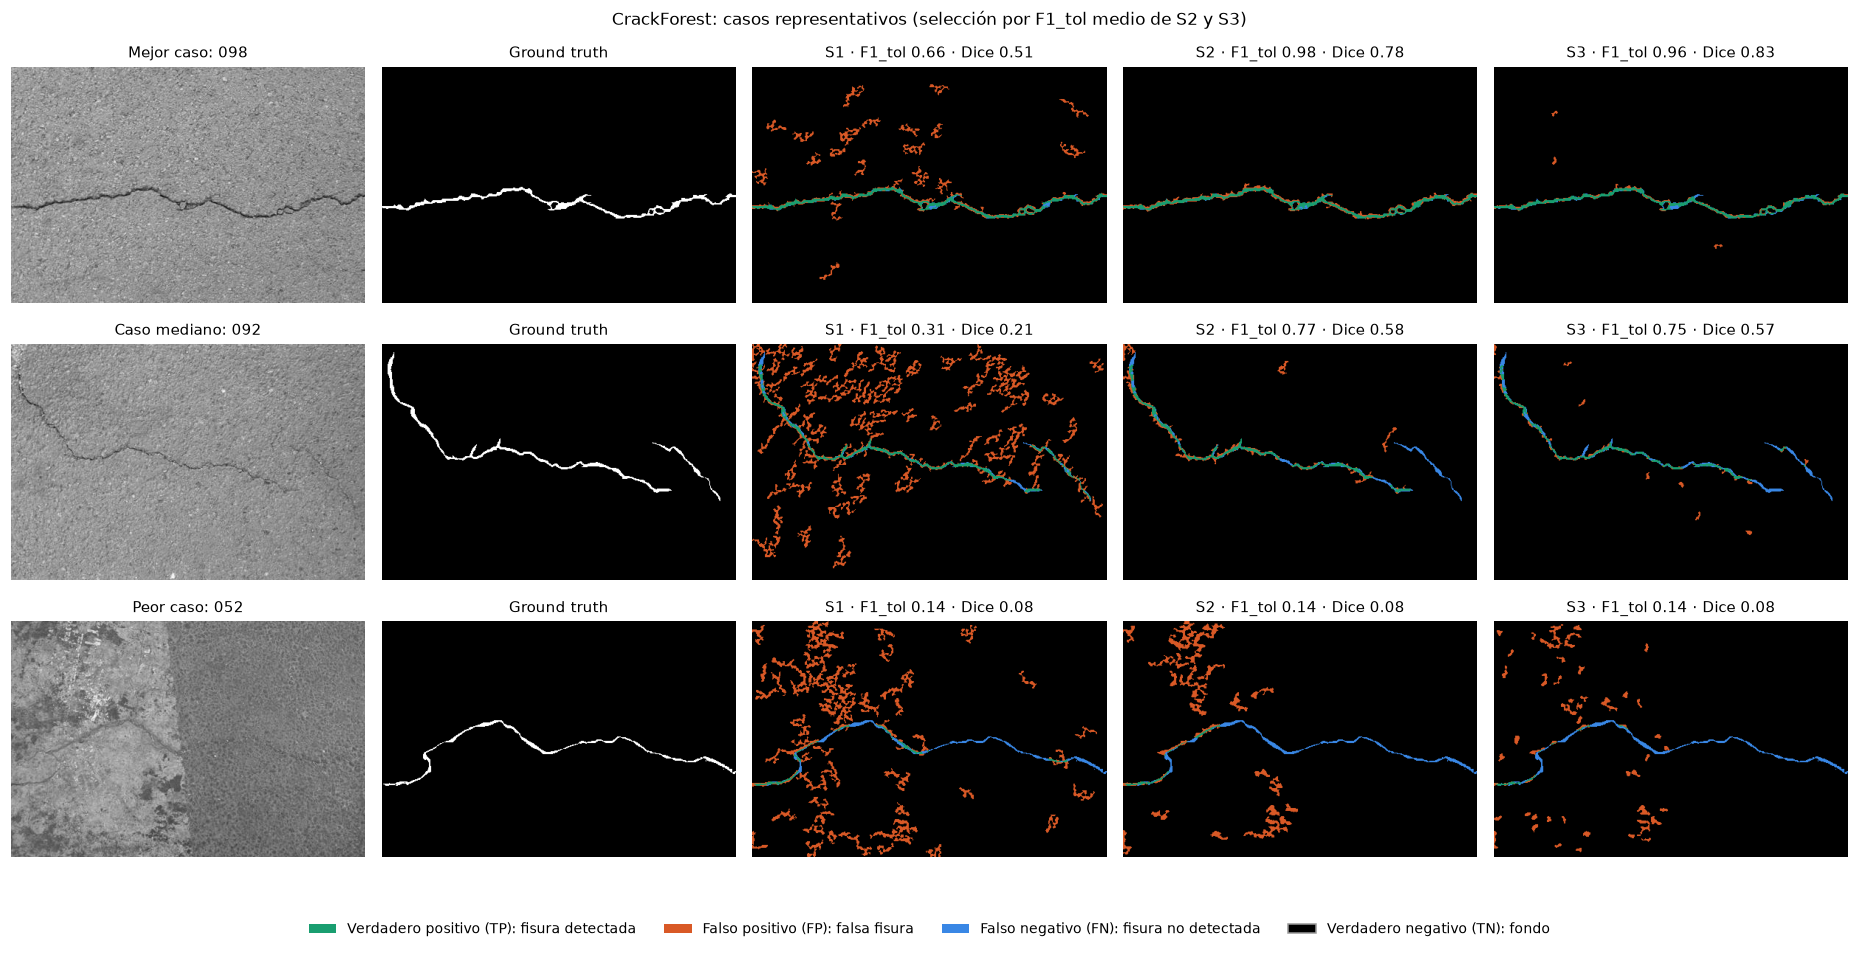

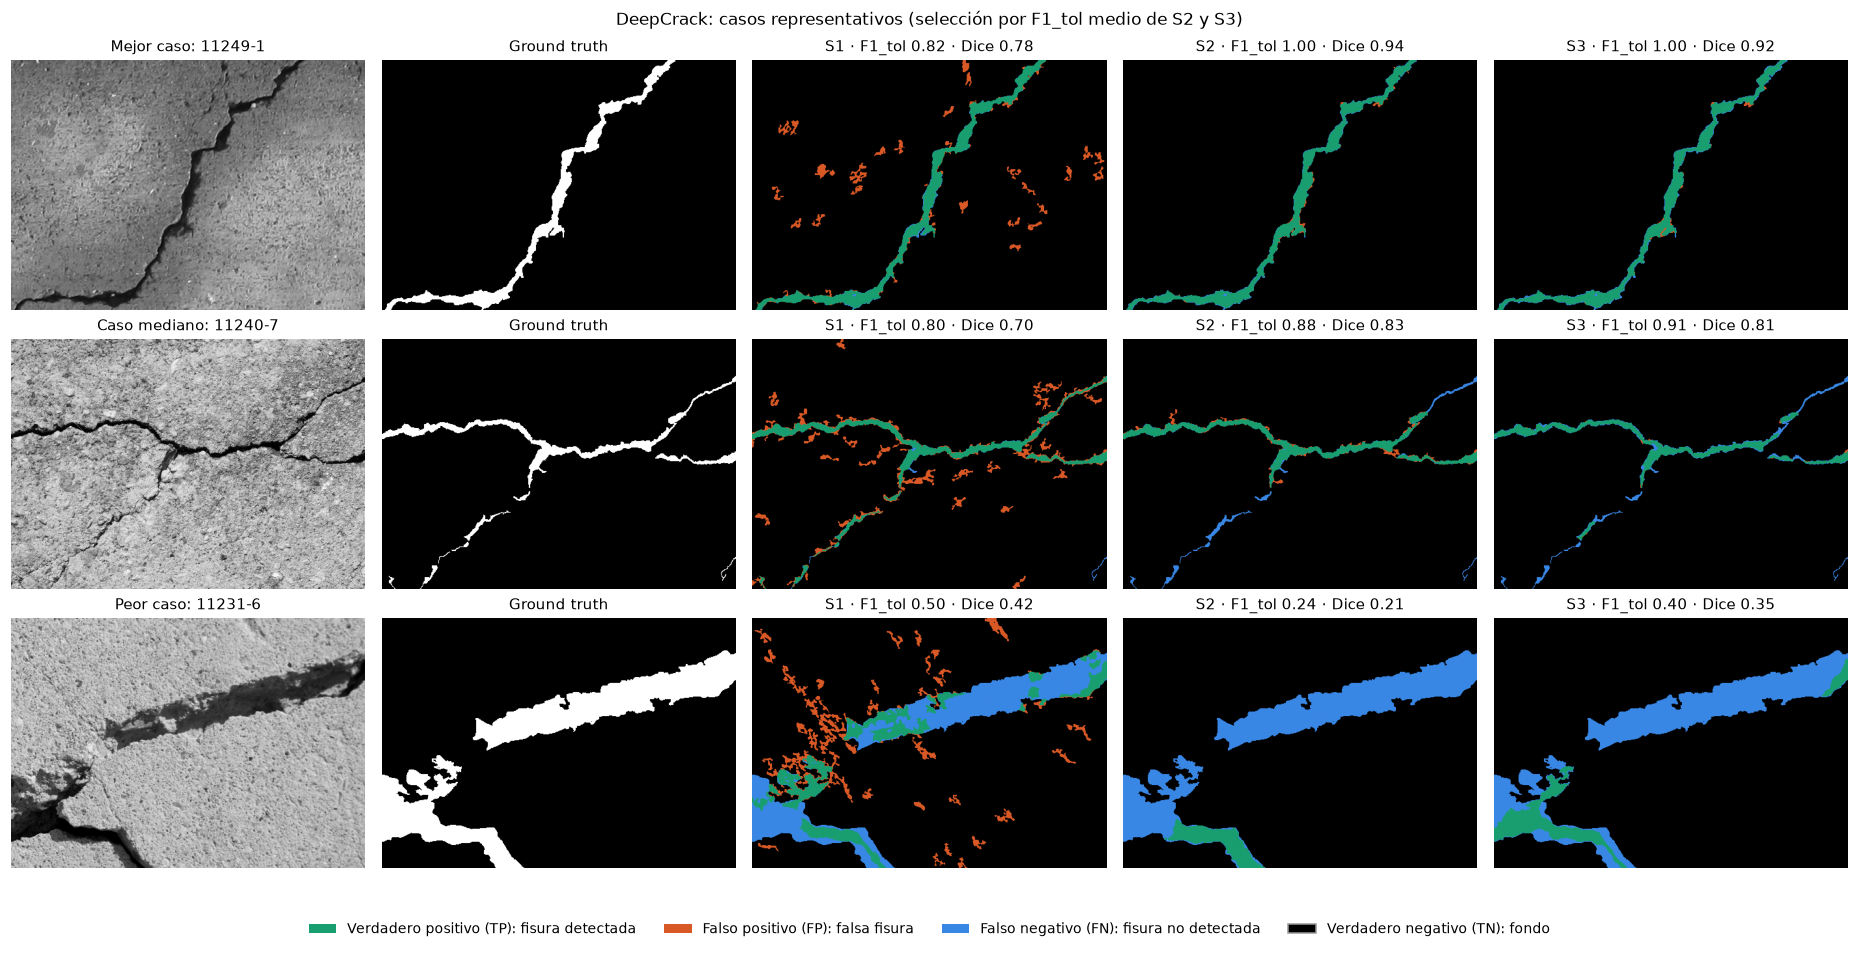

In [24]:
# Casos representativos: mejor, mediano y peor resultado de cada conjunto

def casos_representativos(conjunto):
    """Imágenes de evaluación con el mejor, el mediano y el peor F1_tol medio de S2 y S3."""
    datos = resultados[(resultados["Conjunto"] == conjunto) & (resultados["Método"] != "S1 Otsu")]
    f1_medio = datos.groupby("Imagen")["F1_tol"].mean().sort_values()
    return {"Mejor caso": f1_medio.index[-1],
            "Caso mediano": f1_medio.index[len(f1_medio) // 2],
            "Peor caso": f1_medio.index[0]}


for conjunto in ["CrackForest", "DeepCrack"]:
    casos = casos_representativos(conjunto)
    fig, ejes = plt.subplots(3, 5, figsize=(17, 8.2))
    for fila, (etiqueta, id_imagen) in enumerate(casos.items()):
        m = next(x for x in evaluacion if x["conjunto"] == conjunto and x["id"] == id_imagen)
        ejes[fila, 0].imshow(m["img"], cmap="gray", vmin=0, vmax=255)
        ejes[fila, 0].set_title(f"{etiqueta}: {id_imagen}")
        ejes[fila, 1].imshow(m["gt"], cmap="gray")
        ejes[fila, 1].set_title("Ground truth")
        mascaras, _ = segmentar_con_los_tres(m["img"], conjunto)
        for col, (metodo, S) in enumerate(mascaras.items(), start=2):
            r = evaluar(S, m["gt"])
            ejes[fila, col].imshow(superposicion_errores(S, m["gt"]))
            ejes[fila, col].set_title(f'{metodo.split()[0]} · F1_tol {r["F1_tol"]:.2f} · Dice {r["Dice"]:.2f}')
    for eje in ejes.ravel():
        eje.axis("off")
    fig.suptitle(f"{conjunto}: casos representativos (selección por F1_tol medio de S2 y S3)", fontsize=11)
    plt.tight_layout()
    leyenda_errores(fig)
    plt.savefig(RUTA_RESULTADOS / f"fig09_casos_{conjunto}.png", bbox_inches="tight")
    plt.show()

## 5. Prueba de los segmentadores con una imagen a elección

Esta celda aplica los tres segmentadores, con los parámetros calibrados en la sección 3.5, a cualquier imagen. Hay dos opciones:

- **Opción A, una imagen de los conjuntos de datos.** Se indican el conjunto y el nombre; por ejemplo, `"049"` (la imagen de fisura tenue de la Actividad 1) o `"11125-1"` de DeepCrack. Como tienen *ground truth*, se calculan todas las métricas y se muestran los mapas de errores. La celda indica también el papel de la imagen en el estudio: calibración, evaluación o excluida.
- **Opción B, una imagen propia**, por ejemplo una fotografía de un pavimento, indicada en `RUTA_IMAGEN_PROPIA`. Sin máscara de referencia se muestran solo las detecciones. Se elige el perfil de parámetros más parecido: `"CrackForest"` para fisuras finas o `"DeepCrack"` para fisuras anchas. Las imágenes grandes se reducen a 544 px de lado mayor, porque los parámetros se calibraron con imágenes de ese tamaño y el ancho de la fisura en píxeles debe ser comparable.

Imagen: CrackForest 092 | papel en el estudio: evaluación
Parámetros calibrados utilizados: perfil CrackForest

                              IoU   Dice  Precision  Sensibilidad  F1_tol  clDice  Tiempo (s)
S1 Otsu                     0.118  0.211      0.122         0.775   0.307   0.203       0.005
S2 Crecimiento de regiones  0.412  0.584      0.540         0.635   0.767   0.625       0.022
S3 Watershed                0.395  0.566      0.636         0.510   0.754   0.637       0.041


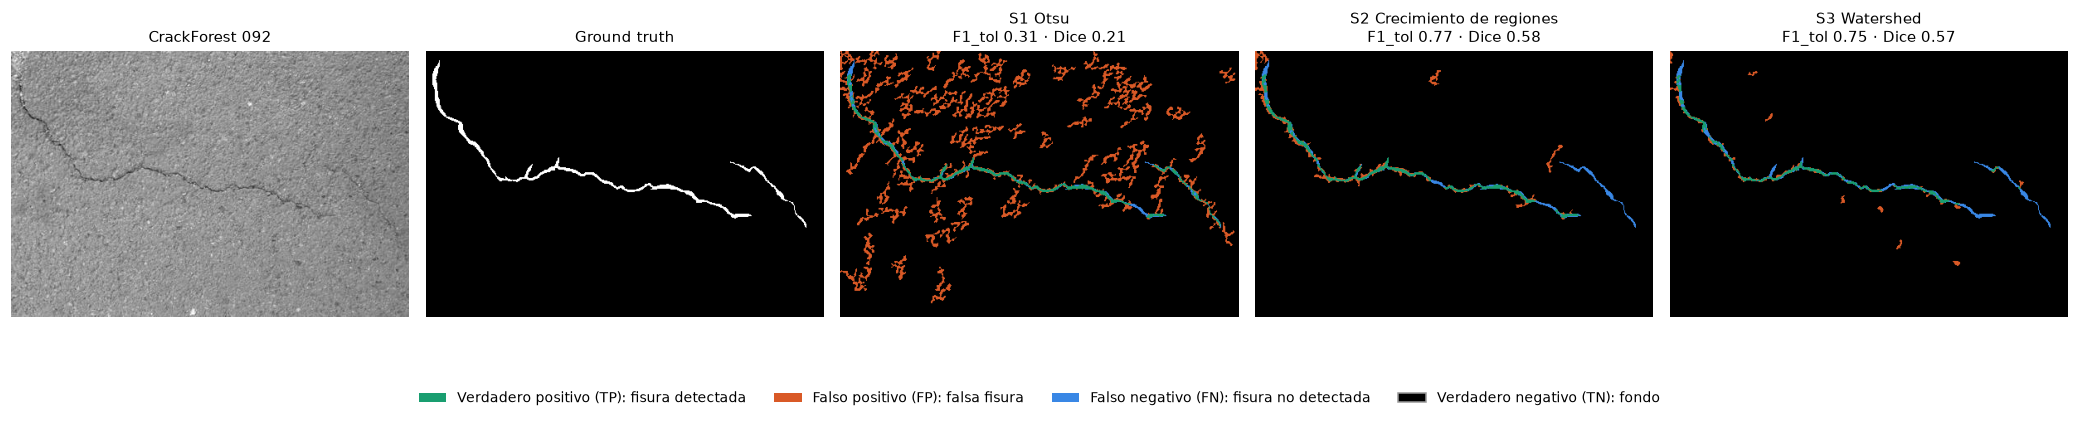

In [25]:
# Prueba de los segmentadores calibrados sobre una imagen a elección (de los conjuntos o propia)

# ---------------- Parámetros que puede modificar el usuario ----------------
# Opción A: una imagen de los conjuntos de datos (tiene ground truth -> se calculan métricas)
CONJUNTO_ELEGIDO = "CrackForest"     # "CrackForest" o "DeepCrack"
IMAGEN_ELEGIDA = "092"               # nombre del archivo sin extensión (p. ej. "049" o "11125-1")
SUBCONJUNTO_DEEPCRACK = "test"       # solo para DeepCrack: "train" o "test"

# Opción B: una imagen propia (si se indica una ruta, tiene prioridad sobre la opción A)
RUTA_IMAGEN_PROPIA = None            # p. ej. r"C:\fotos\pavimento.jpg"
RUTA_GT_PROPIA = None                # opcional: máscara del mismo tamaño (blanco = fisura)
PERFIL_PARAMETROS = "CrackForest"    # parámetros calibrados a usar: "CrackForest" (fisuras finas)
                                     # o "DeepCrack" (fisuras anchas)
LADO_MAXIMO = 544                    # las imágenes propias se reducen a este lado máximo (px); None = no reducir
# ----------------------------------------------------------------------------


def leer_imagen_propia(ruta, ruta_gt=None, lado_maximo=None):
    """Lee una imagen propia en gris (y su máscara opcional), reduciéndola si es muy grande.

    Devuelve
    --------
    img : matriz uint8 en escala de grises.
    gt : matriz booleana o None si no se indicó máscara.
    escala : float, factor de reducción aplicado (1.0 = sin reducir).
    """
    if not Path(ruta).is_file():
        raise FileNotFoundError(f"No existe el archivo: {ruta}")
    img = cv2.imread(str(ruta), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"OpenCV no pudo leer la imagen: {ruta}")
    gt = None
    if ruta_gt is not None:
        etiqueta = cv2.imread(str(ruta_gt), cv2.IMREAD_GRAYSCALE)
        if etiqueta is None or etiqueta.shape != img.shape:
            raise ValueError("La máscara no se pudo leer o no tiene el mismo tamaño que la imagen")
        gt = etiqueta > 127
    escala = 1.0
    if lado_maximo is not None and max(img.shape) > lado_maximo:
        escala = lado_maximo / max(img.shape)
        nuevo = (round(img.shape[1] * escala), round(img.shape[0] * escala))
        img = cv2.resize(img, nuevo, interpolation=cv2.INTER_AREA)
        if gt is not None:
            gt = cv2.resize(gt.astype(np.uint8), nuevo, interpolation=cv2.INTER_NEAREST).astype(bool)
    return img, gt, escala


def papel_en_el_estudio(conjunto, subconjunto, identificador):
    """Indica si la imagen se usó para calibrar, para evaluar, si se excluyó o si no se usó."""
    clave = (conjunto, subconjunto if conjunto == "DeepCrack" else "-", identificador)
    if clave in EXCLUIDAS:
        return "excluida por anotación defectuosa (sección 1.2)"
    if conjunto == "CrackForest":
        en_cal, en_eva = identificador in cfd_calibracion, identificador in cfd_evaluacion
    else:
        en_cal = subconjunto == "train" and identificador in dc_calibracion
        en_eva = subconjunto == "test" and identificador in dc_evaluacion
    return "calibración" if en_cal else "evaluación" if en_eva else "no utilizada en el estudio"


# --- 1. Lectura de la imagen elegida ---
if RUTA_IMAGEN_PROPIA is not None:
    img_usuario, gt_usuario, escala = leer_imagen_propia(RUTA_IMAGEN_PROPIA, RUTA_GT_PROPIA, LADO_MAXIMO)
    perfil = PERFIL_PARAMETROS
    nombre = Path(RUTA_IMAGEN_PROPIA).name
    print(f"Imagen propia: {nombre} | tamaño procesado {img_usuario.shape[1]} x {img_usuario.shape[0]} px"
          + (f" (reducida al {100 * escala:.0f} %)" if escala < 1 else ""))
else:
    subconjunto = SUBCONJUNTO_DEEPCRACK if CONJUNTO_ELEGIDO == "DeepCrack" else None
    disponibles = {"CrackForest": ids_cfd, "DeepCrack": ids_dc_test if subconjunto == "test" else ids_dc_train}
    if IMAGEN_ELEGIDA not in disponibles[CONJUNTO_ELEGIDO]:
        raise ValueError(f"'{IMAGEN_ELEGIDA}' no está entre las imágenes con ground truth de "
                         f"{CONJUNTO_ELEGIDO}" + (f"/{subconjunto}" if subconjunto else ""))
    img_usuario, gt_usuario = cargar_muestra(CONJUNTO_ELEGIDO, subconjunto, IMAGEN_ELEGIDA)
    perfil = CONJUNTO_ELEGIDO
    nombre = f"{CONJUNTO_ELEGIDO} {IMAGEN_ELEGIDA}"
    print(f"Imagen: {nombre} | papel en el estudio: "
          f"{papel_en_el_estudio(CONJUNTO_ELEGIDO, subconjunto, IMAGEN_ELEGIDA)}")
print(f"Parámetros calibrados utilizados: perfil {perfil}\n")

# --- 2. Segmentación con los tres métodos ---
mascaras, tiempos = segmentar_con_los_tres(img_usuario, perfil)

# --- 3. Resultados: con ground truth, métricas y mapas de errores; sin él, solo las detecciones ---
if gt_usuario is not None:
    tabla_usuario = pd.DataFrame({m: {**evaluar(S, gt_usuario), "Tiempo (s)": tiempos[m]}
                                  for m, S in mascaras.items()}).T
    print(tabla_usuario[["IoU", "Dice", "Precision", "Sensibilidad", "F1_tol", "clDice", "Tiempo (s)"]]
          .astype(float).round(3).to_string())
    fig, ejes = plt.subplots(1, 5, figsize=(19, 3.8))
    ejes[0].imshow(img_usuario, cmap="gray", vmin=0, vmax=255)
    ejes[0].set_title(nombre)
    ejes[1].imshow(gt_usuario, cmap="gray")
    ejes[1].set_title("Ground truth")
    for eje, (metodo, S) in zip(ejes[2:], mascaras.items()):
        r = tabla_usuario.loc[metodo]
        eje.imshow(superposicion_errores(S, gt_usuario))
        eje.set_title(f'{metodo}\nF1_tol {r["F1_tol"]:.2f} · Dice {r["Dice"]:.2f}')
    for eje in ejes:
        eje.axis("off")
    plt.tight_layout()
    leyenda_errores(fig)
else:
    print("Sin ground truth: se muestran las detecciones, sin métricas.")
    for metodo, S in mascaras.items():
        print(f"  {metodo:28s} fisura detectada: {100 * S.mean():5.2f} % de la imagen | "
              f"tiempo {tiempos[metodo]:.2f} s")
    fig, ejes = plt.subplots(1, 4, figsize=(17, 4))
    ejes[0].imshow(img_usuario, cmap="gray", vmin=0, vmax=255)
    ejes[0].set_title(nombre)
    for eje, (metodo, S) in zip(ejes[1:], mascaras.items()):
        vista = np.dstack([img_usuario / 255.0] * 3)
        vista[S] = matplotlib.colors.to_rgb("#eda100")             # detección en amarillo
        eje.imshow(vista)
        eje.set_title(f"{metodo}: detección en amarillo")
    for eje in ejes:
        eje.axis("off")
    plt.tight_layout()
plt.show()

## Referencias

Referencias citadas únicamente en este notebook. Las restantes se recogen en la bibliografía del informe.

Blum, H. (1967). A transformation for extracting new descriptors of shape. En W. Wathen-Dunn (Ed.), *Models for the perception of speech and visual form* (pp. 362–380). MIT Press.

Soille, P. (2003). *Morphological image analysis: Principles and applications* (2.ª ed.). Springer.

Zhang, T. Y. y Suen, C. Y. (1984). A fast parallel algorithm for thinning digital patterns. *Communications of the ACM, 27*(3), 236–239.